### Import data

In [1]:
import pandas as pd
from tabulate import tabulate
from IPython.display import display

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 1000)
pd.set_option("display.max_colwidth", None)

In [ ]:
import os
from pathlib import Path

project_root = Path(os.getcwd()).parent
data_raw_dir = project_root / "data" / "raw"
data_processed_dir = project_root / "data" / "processed"
models_dir = project_root / "models"
results_dir = project_root / "results"

data_raw_dir.mkdir(parents=True, exist_ok=True)
data_processed_dir.mkdir(parents=True, exist_ok=True)
models_dir.mkdir(parents=True, exist_ok=True)
results_dir.mkdir(parents=True, exist_ok=True)

print(f"Project root: {project_root}")
print(f"Data raw: {data_raw_dir}")
print(f"Data processed: {data_processed_dir}")
print(f"Models: {models_dir}")

In [ ]:
file_path = (
    data_raw_dir / "INX_Future_Inc_Employee_Performance_CDS_Project2_Data_V1.8.xls"
)
xl = pd.ExcelFile(file_path)
print("Available sheets:", xl.sheet_names)

In [ ]:
copy_file_path = (
    data_processed_dir
    / "INX_Future_Inc_Employee_Performance_CDS_Project2_Data_V1.8.xlsx"
)
writer = pd.ExcelWriter(copy_file_path, engine="xlsxwriter")
for sheet_name in xl.sheet_names:
    df = xl.parse(sheet_name)
    df.to_excel(writer, sheet_name=sheet_name, index=False)
writer.close()

In [4]:
# Load the 'Data Definitions' sheet from the copied file
data_definitions = pd.read_excel(copy_file_path, sheet_name="Data Definitions")

# Correctly fill NaN values forward in the first column to associate each definition with its category
data_definitions["Unnamed: 0"] = data_definitions["Unnamed: 0"].ffill()

# Clean up the DataFrame by removing rows where the second column is NaN
data_definitions.dropna(subset=["Unnamed: 1"], inplace=True)

# cleaned content
print("Cleaned Content of 'Data Definitions' Sheet in Markdown Table:")
print(data_definitions.to_markdown(index=False, tablefmt="pipe"))

Cleaned Content of 'Data Definitions' Sheet in Markdown Table:
| Unnamed: 0                 | Unnamed: 1        |
|:---------------------------|:------------------|
| EmpEducationLevel          | 1 'Below College' |
| EmpEducationLevel          | 2 'College'       |
| EmpEducationLevel          | 3 'Bachelor'      |
| EmpEducationLevel          | 4 'Master'        |
| EmpEducationLevel          | 5 'Doctor'        |
| EmpEnvironmentSatisfaction | 1 'Low'           |
| EmpEnvironmentSatisfaction | 2 'Medium'        |
| EmpEnvironmentSatisfaction | 3 'High'          |
| EmpEnvironmentSatisfaction | 4 'Very High'     |
| EmpJobInvolvement          | 1 'Low'           |
| EmpJobInvolvement          | 2 'Medium'        |
| EmpJobInvolvement          | 3 'High'          |
| EmpJobInvolvement          | 4 'Very High'     |
| EmpJobSatisfaction         | 1 'Low'           |
| EmpJobSatisfaction         | 2 'Medium'        |
| EmpJobSatisfaction         | 3 'High'          |
| EmpJobSatisfactio

In [5]:
# Load the 'INX_Future_Inc_Employee_Perform' sheet into a DataFrame
data = pd.read_excel(copy_file_path, sheet_name="INX_Future_Inc_Employee_Perform")

print(data.shape)
for idx, col in enumerate(data.columns):
    print(f"{idx}: {col}")

(1200, 28)
0: EmpNumber
1: Age
2: Gender
3: EducationBackground
4: MaritalStatus
5: EmpDepartment
6: EmpJobRole
7: BusinessTravelFrequency
8: DistanceFromHome
9: EmpEducationLevel
10: EmpEnvironmentSatisfaction
11: EmpHourlyRate
12: EmpJobInvolvement
13: EmpJobLevel
14: EmpJobSatisfaction
15: NumCompaniesWorked
16: OverTime
17: EmpLastSalaryHikePercent
18: EmpRelationshipSatisfaction
19: TotalWorkExperienceInYears
20: TrainingTimesLastYear
21: EmpWorkLifeBalance
22: ExperienceYearsAtThisCompany
23: ExperienceYearsInCurrentRole
24: YearsSinceLastPromotion
25: YearsWithCurrManager
26: Attrition
27: PerformanceRating


The dataset consists of 1200 employee records across 28 features, including demographic, job-related, and satisfaction metrics. Based on the ‘Data Definitions’ sheet, several categorical features such as satisfaction scores, education levels, and performance ratings are encoded numerically, which helps in mapping human factors into measurable patterns. Each record provides a detailed profile of an employee, from age and job role to work-life balance and relationship satisfaction. With this structured setup, the data offers a solid foundation for exploring how different aspects of an employee’s personal and professional environment relate to their performance rating, which will drive the analysis and modeling in the later stages.

### Imports & functions

In [ ]:
# pip install insightfulpy==0.1.7
from insightfulpy.eda import *

In [7]:
import warnings
import logging

warnings.filterwarnings("ignore")
logging.getLogger("matplotlib").setLevel(logging.WARNING)

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno

# import dtale
from scipy import stats
from scipy.stats import (
    chi2_contingency,
    fisher_exact,
    pearsonr,
    spearmanr,
    ttest_ind,
    mannwhitneyu,
    shapiro,
)
from scipy.cluster.hierarchy import linkage, dendrogram, leaves_list
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

----

In [ ]:
import sys
import os

sys.path.insert(0, os.path.abspath(os.path.join(os.getcwd(), "..")))

from src.statistical_analysis import (
    normality_test_with_skew_kurt,
    spearman_correlation,
    calculate_vif,
)

---

### Basic checks and understand the data

In [ ]:
import sys
import os

sys.path.insert(0, os.path.abspath(os.path.join(os.getcwd(), "..")))

from src.utils import memory_usage, dataframe_memory_usage, garbage_collection

In [10]:
if __name__ == "__main__":
    memory_usage()

Memory Usage: 225.35 MB


In [11]:
dataframe_memory_usage(data)

DataFrame Memory Usage: 0.85 MB


0.8464288711547852

---

The actual memory used by the DataFrame is approximately 0.85 MB, which is quite efficient considering it holds 1200 records with 28 features. Although the environment reports a broader memory footprint of around 302.75 MB, the dataset itself is lightweight and manageable for processing. This allows smooth exploration and modeling without performance issues, making it convenient to analyze patterns and relationships in employee performance data.

In [12]:
print(data.shape)
for idx, col in enumerate(data.columns):
    print(f"{idx}: {col}")

(1200, 28)
0: EmpNumber
1: Age
2: Gender
3: EducationBackground
4: MaritalStatus
5: EmpDepartment
6: EmpJobRole
7: BusinessTravelFrequency
8: DistanceFromHome
9: EmpEducationLevel
10: EmpEnvironmentSatisfaction
11: EmpHourlyRate
12: EmpJobInvolvement
13: EmpJobLevel
14: EmpJobSatisfaction
15: NumCompaniesWorked
16: OverTime
17: EmpLastSalaryHikePercent
18: EmpRelationshipSatisfaction
19: TotalWorkExperienceInYears
20: TrainingTimesLastYear
21: EmpWorkLifeBalance
22: ExperienceYearsAtThisCompany
23: ExperienceYearsInCurrentRole
24: YearsSinceLastPromotion
25: YearsWithCurrManager
26: Attrition
27: PerformanceRating


---

**Categorization of Variables by Domain:**  

| **Domain**                     | **Variables**                                                                                                       |  
|---------------------------------|---------------------------------------------------------------------------------------------------------------------|  
| **1. Personal Demographics**    | `Age`, `Gender`, `EducationBackground`, `MaritalStatus`, `DistanceFromHome`, `EmpEducationLevel`                    |  
| **2. Job-Related Information**  | `EmpDepartment`, `EmpJobRole`, `BusinessTravelFrequency`, `EmpJobLevel`, `OverTime`                                 |  
| **3. Satisfaction & Engagement**| `EmpEnvironmentSatisfaction`, `EmpJobInvolvement`, `EmpJobSatisfaction`, `EmpRelationshipSatisfaction`, `EmpWorkLifeBalance` |  
| **4. Work Experience**          | `NumCompaniesWorked`, `TotalWorkExperienceInYears`, `ExperienceYearsAtThisCompany`, `ExperienceYearsInCurrentRole`, `YearsSinceLastPromotion` |  
| **5. Compensation & Benefits**  | `EmpHourlyRate`, `EmpLastSalaryHikePercent`                                                                         |  
| **6. Professional Development** | `TrainingTimesLastYear`                                                                                             |  
| **7. Organizational Structure** | `YearsWithCurrManager`                                                                                              |  
| **8. Performance Metrics**      | `Attrition`, `PerformanceRating` (Target Variable)                                                                  |  
| **9. Identification**           | `EmpNumber`                                                                                                         |  

---

**Key Notes:**  
- **PerformanceRating** is explicitly the **target variable** for modeling, aligning with the project’s goal to predict employee performance.  
- **Attrition** is categorized under *Performance Metrics* but is **not the target** here; it may serve as a predictor.  
- **YearsWithCurrManager** reflects organizational dynamics (e.g., manager-employee relationships).  
- **TrainingTimesLastYear** falls under *Professional Development*, as it relates to skill enhancement.  
- **DistanceFromHome** is grouped under *Personal Demographics* (lifestyle/commute influence).  

This categorization aligns with HR analytics standards and the project’s focus on performance analysis.

---

In [13]:
data.head().T

,0,1,2,3,4
EmpNumber,E1001000,E1001006,E1001007,E1001009,E1001010
Age,32,47,40,41,60
Gender,Male,Male,Male,Male,Male
EducationBackground,Marketing,Marketing,Life Sciences,Human Resources,Marketing
MaritalStatus,Single,Single,Married,Divorced,Single
EmpDepartment,Sales,Sales,Sales,Human Resources,Sales
EmpJobRole,Sales Executive,Sales Executive,Sales Executive,Manager,Sales Executive
BusinessTravelFrequency,Travel_Rarely,Travel_Rarely,Travel_Frequently,Travel_Rarely,Travel_Rarely
DistanceFromHome,10,14,5,10,16
EmpEducationLevel,3,4,4,4,4


In [14]:
detect_mixed_data_types(data)

'No mixed data types detected!'

In [15]:
cat_high_cardinality(data)

high_cardinality_columns


['EmpNumber']

Missing Values Summary:
No missing values found.

Infinite Values Summary:
No infinite values found.

Number of duplicate rows: 0



<Figure size 2000x800 with 0 Axes>

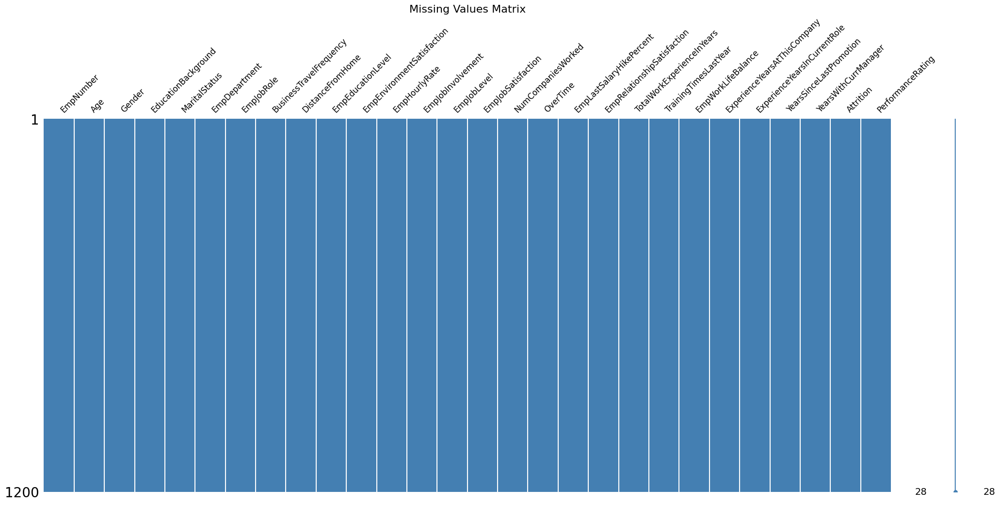

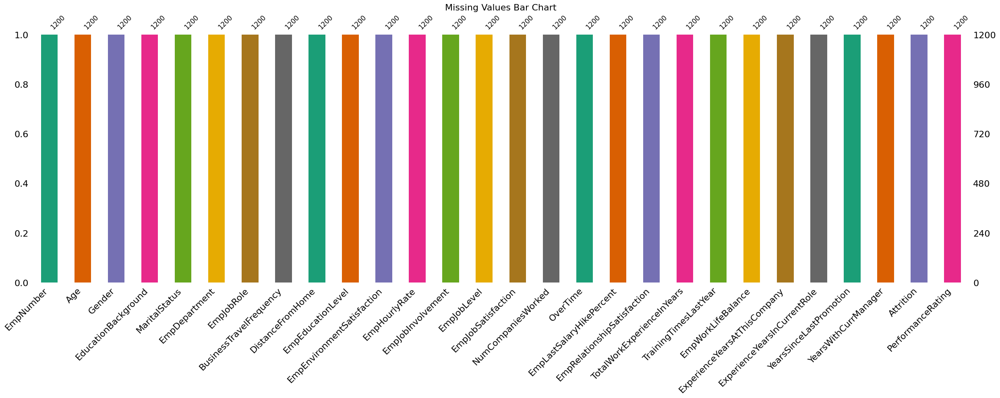

In [16]:
missing_inf_values(data)
print(f"\nNumber of duplicate rows: {data.duplicated().sum()}\n")
duplicates = data[data.duplicated()]
duplicates
show_missing(data)

In [17]:
data_negative_values = data.select_dtypes(include=[np.number]).lt(0).sum()
data_negative_values = data_negative_values[data_negative_values > 0].sort_values(
    ascending=False
)
print("Columns with Negative Values (Sorted):\n", data_negative_values)

Columns with Negative Values (Sorted):
 Series([], dtype: int64)


In [18]:
data.dtypes.value_counts()

int64     19
object     9
Name: count, dtype: int64

The dataset appears to be clean and well-structured. There are no missing or infinite values, and no duplicate rows were found, which ensures reliability during analysis. The column EmpNumber, while high in cardinality, serves as a unique identifier and doesn't impact the modeling directly. All columns have consistent data types with 19 being numeric (int64) and 9 categorical (object), and no negative values exist where they shouldn't. This cleanliness provides a strong base to proceed confidently with deeper exploratory analysis and modeling without needing extensive preprocessing.

In [19]:
columns_info("Dataset Overview", data)


======== Dataset Overview: ===========

Index Col Index  Attribute                      Data Type       Range                          Distinct Count
----- ---------- ------------------------------ --------------- ------------------------------ ---------------
1     1          Age                            int64           18 - 60                        43
2     8          DistanceFromHome               int64           1 - 29                         29
3     9          EmpEducationLevel              int64           1 - 5                          5
4     10         EmpEnvironmentSatisfaction     int64           1 - 4                          4
5     11         EmpHourlyRate                  int64           30 - 100                       71
6     12         EmpJobInvolvement              int64           1 - 4                          4
7     13         EmpJobLevel                    int64           1 - 5                          5
8     14         EmpJobSatisfaction             int64   

In [20]:
data = data.drop("EmpNumber", axis=1)

categorical_features = [
    "EmpEducationLevel",
    "EmpEnvironmentSatisfaction",
    "EmpJobInvolvement",
    "EmpJobLevel",
    "EmpJobSatisfaction",
    "EmpRelationshipSatisfaction",
    "EmpWorkLifeBalance",
    "PerformanceRating",
    "TrainingTimesLastYear",
]
for col in categorical_features:
    data[col] = data[col].astype("category")

# Convert object types to categorical where appropriate
object_features = [
    "Gender",
    "EducationBackground",
    "MaritalStatus",
    "EmpDepartment",
    "EmpJobRole",
    "BusinessTravelFrequency",
    "OverTime",
    "Attrition",
]
for col in object_features:
    data[col] = data[col].astype("category")

At this stage, the structure is clear and refined. Personal identifiers like EmpNumber have been removed to maintain focus on meaningful attributes. Encoded scores for satisfaction, involvement, and performance are now properly treated as categorical, respecting their ordinal nature. Other descriptive fields like gender, department, and job roles have also been cast to category types for better efficiency and interpretability. With these adjustments, the data is in a ready state to dive deeper into patterns that influence employee outcomes.

In [21]:
columns_info("Dataset Overview", data)


======== Dataset Overview: ===========

Index Col Index  Attribute                      Data Type       Range                          Distinct Count
----- ---------- ------------------------------ --------------- ------------------------------ ---------------
1     1          Gender                         category        N/A                            2
2     2          EducationBackground            category        N/A                            6
3     3          MaritalStatus                  category        N/A                            3
4     4          EmpDepartment                  category        N/A                            6
5     5          EmpJobRole                     category        N/A                            19
6     6          BusinessTravelFrequency        category        N/A                            3
7     8          EmpEducationLevel              category        N/A                            5
8     9          EmpEnvironmentSatisfaction     category  

In [22]:
analyze_data(data)





















=== Numerical Analysis ===
|    | Variable                     |    N |    Mean |      SD |     SE |   95% Conf. |   Interval |
|---:|:-----------------------------|-----:|--------:|--------:|-------:|------------:|-----------:|
|  0 | Age                          | 1200 | 36.9183 |  9.0873 | 0.2623 |     36.4037 |    37.433  |
|  1 | DistanceFromHome             | 1200 |  9.1658 |  8.1766 | 0.236  |      8.7027 |     9.6289 |
|  2 | EmpHourlyRate                | 1200 | 65.9817 | 20.2113 | 0.5835 |     64.837  |    67.1264 |
|  3 | NumCompaniesWorked           | 1200 |  2.665  |  2.4694 | 0.0713 |      2.5251 |     2.8049 |
|  4 | EmpLastSalaryHikePercent     | 1200 | 15.2225 |  3.6259 | 0.1047 |     15.0171 |    15.4279 |
|  5 | TotalWorkExperienceInYears   | 1200 | 11.33   |  7.7972 | 0.2251 |     10.8884 |    11.7716 |
|  6 | ExperienceYearsAtThisCompany | 1200 |  7.0775 |  6.2369 | 0.18   |      6.7243 |     7.4307 |
|  7 | ExperienceYearsInCurrentRole | 1200 |

Most employees fall between 30 and 40 years of age, with an average of nearly 37. Their work experience and tenure at the company reflect a stable workforce, but some have relatively short time with their current manager or since their last promotion, which might hint at dissatisfaction or growth stagnation. Travel frequency leans heavily toward "Travel_Rarely," and overtime appears limited to a smaller segment. Job roles and departments show high variation, though roles like "Sales Executive" and "Developer" dominate. Satisfaction-related variables lean toward higher ratings, suggesting general contentment, but attrition, though low overall, still affects nearly 15%—a non-negligible figure. Most performance ratings sit at "Excellent," with only a small fraction rated "Outstanding," possibly indicating a tough performance evaluation curve or under-recognition. These early findings already hint at areas worth deeper exploration—especially around promotions, job roles, and the gaps between satisfaction and actual performance outcomes.

# Exploratory data analysis (EDA)

### Descriptive Statistics


Value counts and percentages for Performancerating:

|   Performancerating |   Count |   % Total |
|--------------------:|--------:|----------:|
|                   3 |     874 |     72.83 |
|                   2 |     194 |     16.17 |
|                   4 |     132 |     11    |


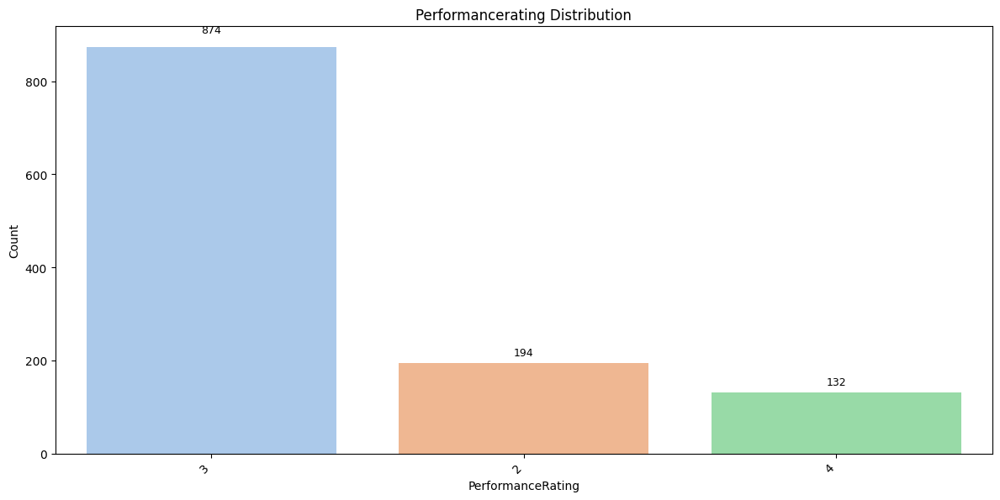

In [23]:
cat_analyze_and_plot(data, "PerformanceRating")


Value counts and percentages for Empdepartment and Performancerating:

| Empdepartment          |   2 |   3 |   4 |   Count |   % Total |   % 2 |   % 3 |   % 4 |
|:-----------------------|----:|----:|----:|--------:|----------:|------:|------:|------:|
| Sales                  |  87 | 251 |  35 |     373 |     31.08 | 23.32 | 67.29 |  9.38 |
| Development            |  13 | 304 |  44 |     361 |     30.08 |  3.6  | 84.21 | 12.19 |
| Research & Development |  68 | 234 |  41 |     343 |     28.58 | 19.83 | 68.22 | 11.95 |
| Human Resources        |  10 |  38 |   6 |      54 |      4.5  | 18.52 | 70.37 | 11.11 |
| Finance                |  15 |  30 |   4 |      49 |      4.08 | 30.61 | 61.22 |  8.16 |
| Data Science           |   1 |  17 |   2 |      20 |      1.67 |  5    | 85    | 10    |


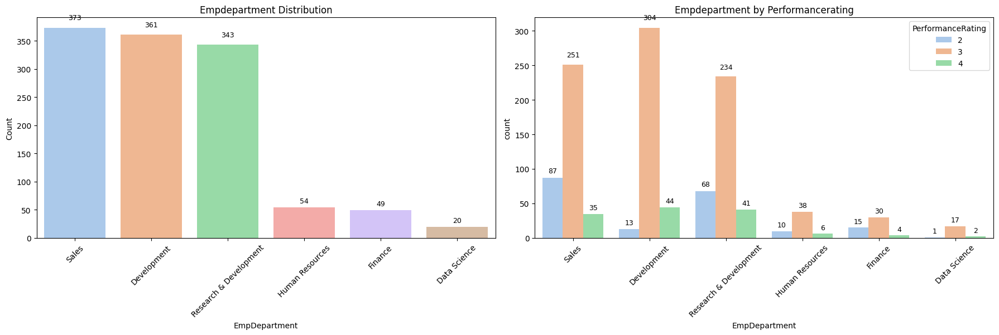

In [24]:
cat_analyze_and_plot(data, "EmpDepartment", "PerformanceRating")

Most employees are rated as "Excellent" (Rating 3), covering nearly 73% of the workforce, while "Good" (Rating 2) and "Outstanding" (Rating 4) are less common, at about 16% and 11% respectively. When broken down by department, Development stands out with over 84% of its employees rated as Excellent and very few in the Good category, indicating strong performance within that group. Data Science and Human Resources also show high proportions of Excellent ratings despite their small size. On the other hand, Sales and Finance have notably higher shares of Good ratings, suggesting more performance variability or challenges in meeting expectations. These departmental differences offer a clear direction for further digging into role demands, expectations, or perhaps even managerial influence.

In [25]:
grouped_summary(data, groupby="PerformanceRating")

=== Summary Grouped by 'PerformanceRating' ===


Grouped by PerformanceRating                                                            
                                                                                       Missing      Overall            2            3            4 P-Value
n                                                                                                      1200          194          874          132        
Age, mean (SD)                                                                               0   36.9 (9.1)   37.8 (9.3)   36.8 (9.0)   36.5 (9.4)   0.315
Gender, n (%)                           Female                                                   475 (39.6)    75 (38.7)   349 (39.9)    51 (38.6)   0.922
                                        Male                                                     725 (60.4)   119 (61.3)   525 (60.1)    81 (61.4)        
EducationBackground, n (%)              Human Resources                                            21 (1.8)      3 (1.5)     16 (1.8)      2 (1.5)   0.422
                                        Life Sciences                                            492 (41.0)    78 (40.2)   357 (40.8)    57 (43.2)        
                                        Marketing                                                137 (11.4)    29 (14.9)    94 (10.8)    14 (10.6)        
                                        Medical                                                  384 (32.0)    63 (32.5)   281 (32.2)    40 (30.3)        
                                        Other                                                      66 (5.5)      3 (1.5)     56 (6.4)      7 (5.3)        
                                        Technical Degree                                          100 (8.3)     18 (9.3)     70 (8.0)     12 (9.1)        
MaritalStatus, n (%)                    Divorced                                                 268 (22.3)    37 (19.1)   205 (23.5)    26 (19.7)   0.189
                                        Married                                                  548 (45.7)   100 (51.5)   393 (45.0)    55 (41.7)        
                                        Single                                                   384 (32.0)    57 (29.4)   276 (31.6)    51 (38.6)        
EmpDepartment, n (%)                    Data Science                                               20 (1.7)      1 (0.5)     17 (1.9)      2 (1.5)  <0.001
                                        Development                                              361 (30.1)     13 (6.7)   304 (34.8)    44 (33.3)        
                                        Finance                                                    49 (4.1)     15 (7.7)     30 (3.4)      4 (3.0)        
                                        Human Resources                                            54 (4.5)     10 (5.2)     38 (4.3)      6 (4.5)        
                                        Research & Development                                   343 (28.6)    68 (35.1)   234 (26.8)    41 (31.1)        
                                        Sales                                                    373 (31.1)    87 (44.8)   251 (28.7)    35 (26.5)        
EmpJobRole, n (%)                       Data Scientist                                             20 (1.7)      1 (0.5)     17 (1.9)      2 (1.5)  <0.001
                                        Developer                                                236 (19.7)      6 (3.1)   199 (22.8)    31 (23.5)        
                                        Finance Manager                                            49 (4.1)     15 (7.7)     30 (3.4)      4 (3.0)        
                                        Healthcare Representative                                  33 (2.8)      8 (4.1)     22 (2.5)      3 (2.3)        
                                        Human Resources                                            45 (3.8)      9 (4.6)     31 (3.5)      5 (3.8)        
                                    

Most performance groups appear evenly distributed across age, gender, education, and marital status, showing no significant differences. However, key distinctions emerge in departmental roles. Development and Data Science are heavily weighted toward higher performance ratings, whereas Sales and Finance lean more toward lower ratings, highlighting functional disparities. Satisfaction scores, particularly in environment and work-life balance, show strong positive correlations with higher ratings. OverTime and salary hike percentages also vary—top performers often received sharper hikes. Job level and tenure don’t shift dramatically, but employees with longer experience in the company or in current roles tend to skew toward “Good” ratings, not necessarily “Outstanding.” Promotions and time with current managers are noticeably lower among the highest performers, hinting at faster progress or better leadership alignment. The significance in these areas suggests that beyond general satisfaction, recognition through hikes and healthy work-life dynamics may play an influential role in pushing performance to the top.

In [26]:
columns_info("Dataset Overview", data)


======== Dataset Overview: ===========

Index Col Index  Attribute                      Data Type       Range                          Distinct Count
----- ---------- ------------------------------ --------------- ------------------------------ ---------------
1     1          Gender                         category        N/A                            2
2     2          EducationBackground            category        N/A                            6
3     3          MaritalStatus                  category        N/A                            3
4     4          EmpDepartment                  category        N/A                            6
5     5          EmpJobRole                     category        N/A                            19
6     6          BusinessTravelFrequency        category        N/A                            3
7     8          EmpEducationLevel              category        N/A                            5
8     9          EmpEnvironmentSatisfaction     category  

In [27]:
num_summary(data)

,Count,Unique,Mean,Std,Min,25%,50%,75%,Max,Mode,Range,IQR,Variance,Skewness,Kurtosis,Shapiro-Wilk Stat,Shapiro-Wilk p-value
Age,1200.0,43.0,36.9183,9.0873,18.0,30.0,36.0,43.0,60.0,34.0,42.0,13.0,82.5788,0.3841,-0.4310,0.9790,0.0
DistanceFromHome,1200.0,29.0,9.1658,8.1766,1.0,2.0,7.0,14.0,29.0,2.0,28.0,12.0,66.8574,0.9630,-0.2420,0.8570,0.0
EmpHourlyRate,1200.0,71.0,65.9817,20.2113,30.0,48.0,66.0,83.0,100.0,66.0,70.0,35.0,408.4967,-0.0352,-1.1869,0.9559,0.0
NumCompaniesWorked,1200.0,10.0,2.6650,2.4694,0.0,1.0,2.0,4.0,9.0,1.0,9.0,3.0,6.0979,1.0486,0.0689,0.8463,0.0
EmpLastSalaryHikePercent,1200.0,15.0,15.2225,3.6259,11.0,12.0,14.0,18.0,25.0,14.0,14.0,6.0,13.1473,0.8087,-0.2997,0.9042,0.0
TotalWorkExperienceInYears,1200.0,40.0,11.3300,7.7972,0.0,6.0,10.0,15.0,40.0,10.0,40.0,9.0,60.7968,1.0869,0.8056,0.9103,0.0
ExperienceYearsAtThisCompany,1200.0,37.0,7.0775,6.2369,0.0,3.0,5.0,10.0,40.0,5.0,40.0,7.0,38.8989,1.7891,4.0580,0.8360,0.0
ExperienceYearsInCurrentRole,1200.0,19.0,4.2917,3.6137,0.0,2.0,3.0,7.0,18.0,2.0,18.0,5.0,13.0591,0.8882,0.4380,0.8999,0.0
YearsSinceLastPromotion,1200.0,16.0,2.1942,3.2216,0.0,0.0,1.0,3.0,15.0,0.0,15.0,3.0,10.3784,1.9749,3.5391,0.7046,0.0
YearsWithCurrManager,1200.0,18.0,4.1050,3.5416,0.0,2.0,3.0,7.0,17.0,2.0,17.0,5.0,12.5428,0.8132,0.1482,0.8988,0.0


In [28]:
cat_summary(data)

,Count,Unique,Top,Freq,Top %
Gender,1200,2,Male,725,60.42%
EducationBackground,1200,6,Life Sciences,492,41.00%
MaritalStatus,1200,3,Married,548,45.67%
EmpDepartment,1200,6,Sales,373,31.08%
EmpJobRole,1200,19,Sales Executive,270,22.50%
BusinessTravelFrequency,1200,3,Travel_Rarely,846,70.50%
EmpEducationLevel,1200,5,3,449,37.42%
EmpEnvironmentSatisfaction,1200,4,3,367,30.58%
EmpJobInvolvement,1200,4,3,724,60.33%
EmpJobLevel,1200,5,2,441,36.75%


Age ranges from 18 to 60, with a mean of 36.9 and standard deviation of 9.1, suggesting a mature workforce. Distance from home varies up to 29 km, averaging 9.2 km. Hourly rate spans from 30 to 100, clustering around 66. Most employees (mode = 1) have worked at one previous company, though it goes up to 9. Salary hikes average 15.2%, peaking at 25%. Total work experience sits at 11.3 years on average, while company tenure averages 7.1 years and role-specific tenure is around 4.3 years. Only 2.2 years have passed since last promotion on average, and time with the current manager is about 4.1 years. Skewness is notable in experience and promotion variables, all positively skewed. Among categories, 60.4% are male, 41% have a Life Sciences background, 45.7% are married, and 31.1% work in Sales. Sales Executive is the top job role (22.5%), and 70.5% travel rarely. Most employees (37.4%) have education level 3, and 60.3% show high job involvement. Over 70% don’t work overtime. The dominant performance rating is 3, representing 72.8% of the population.

### Univariate Analysis

#### num_analysis

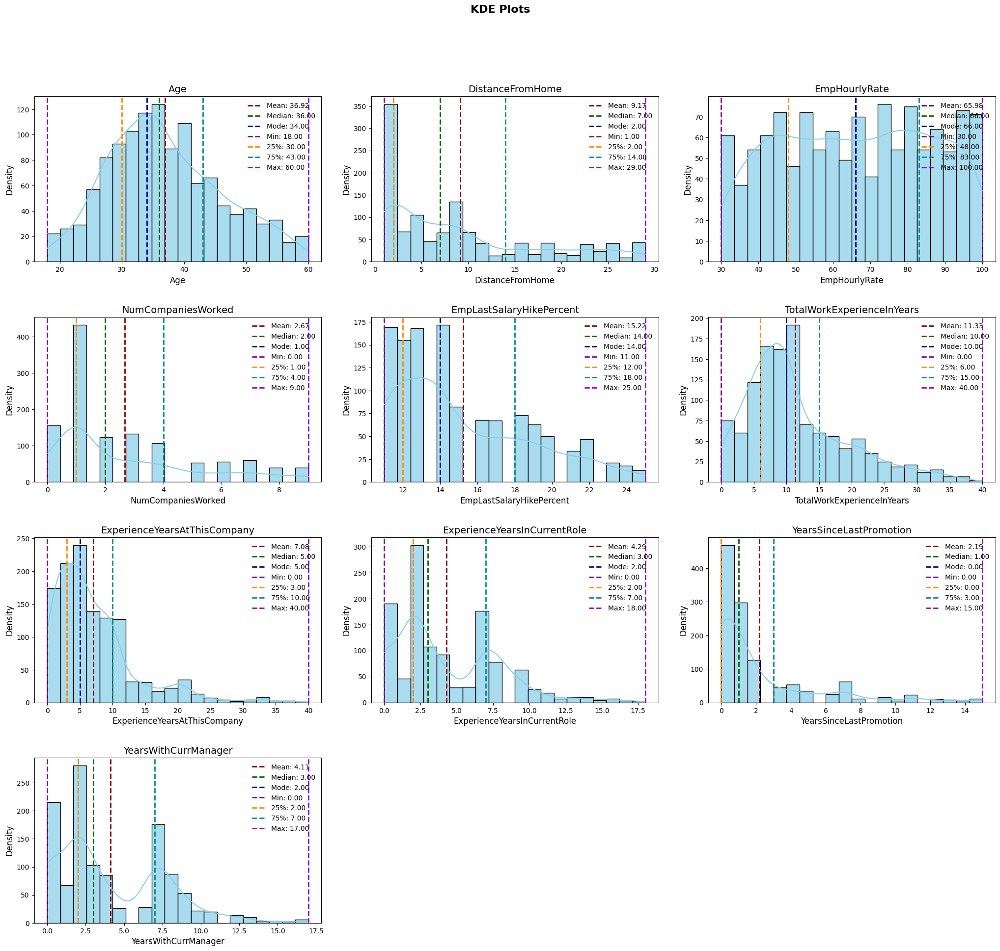

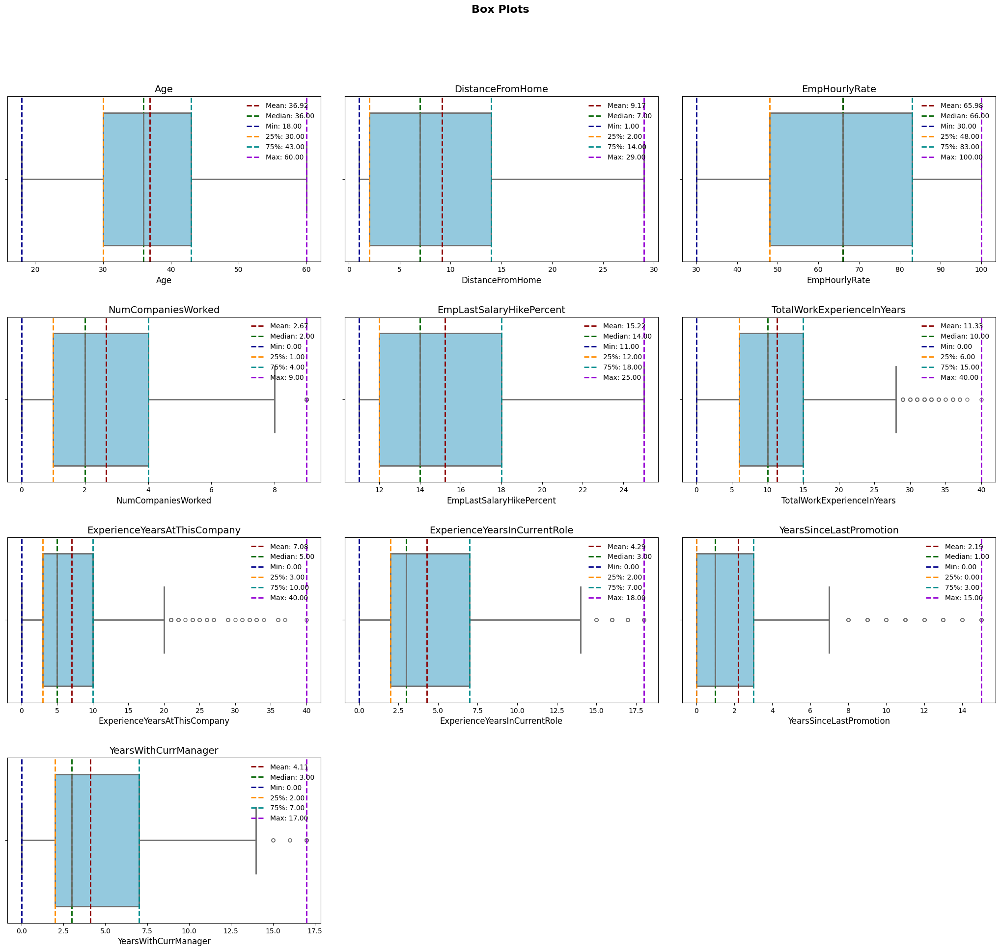

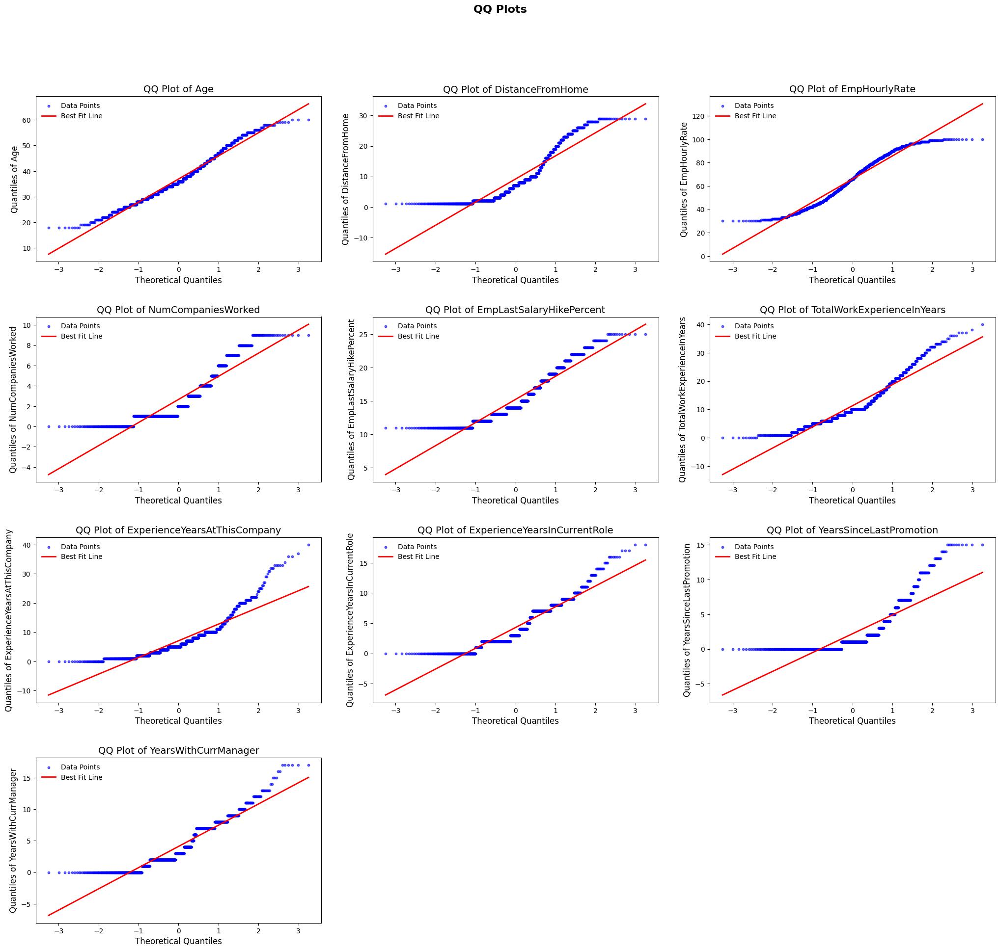

In [29]:
kde_batches(data, batch_num=1)
box_plot_batches(data, batch_num=1)
qq_plot_batches(data, batch_num=1)

The charts indicate clear numerical trends and patterns across performance levels. Among all employees, 72.8% fall into Rating 3 (“Excellent”), while only 16.2% are in Rating 2 (“Good”) and just 11% achieve Rating 4 (“Outstanding”). Departments like Development have a disproportionately high concentration of Rating 3 (84.2%), with only 3.6% in Rating 2, suggesting consistent high performance. On the other hand, Sales shows a broader spread—23.3% in Rating 2 and only 9.4% in Rating 4—indicating greater variation and possibly performance challenges.

Environment Satisfaction plays a crucial role: 46.4% of Rating 2 employees report the lowest satisfaction score (1), while only 9.8% of Rating 4 employees fall into that category. In contrast, Ratings 3 and 4 are dominated by satisfaction levels 3 and 4, together making up over 70% for both groups. A similar pattern appears in Work-Life Balance—19.7% of Rating 4 employees score the highest level (4: “Best”), compared to just 6.2% of Rating 2.

Salary hike percentages further highlight a disparity: Rating 4 employees receive an average hike of 20.7%, compared to 15.1% for Rating 2 and 14.4% for Rating 3. OverTime also correlates with lower performance: 79.9% of Rating 2 employees don’t work overtime, yet a greater proportion of Rating 3 and 4 employees are in the “Yes” category, showing that moderate, well-compensated extra effort may support stronger ratings.

Experience dynamics show a reverse curve—Rating 2 employees have the highest average tenure at the company (9.1 years), while Ratings 3 and 4 sit at 6.7 and 6.8 years respectively. The same applies to time since last promotion: Rating 2 averages 3.7 years while Ratings 3 and 4 stay below 2 years, suggesting that longer stagnation might lower perceived performance.

Overall, the charts reinforce that higher ratings align with better satisfaction scores, higher recognition (via salary hikes), timely promotions, and healthier work-life balance, while departments and roles have strong influence over performance distribution.

#### cat_analysis

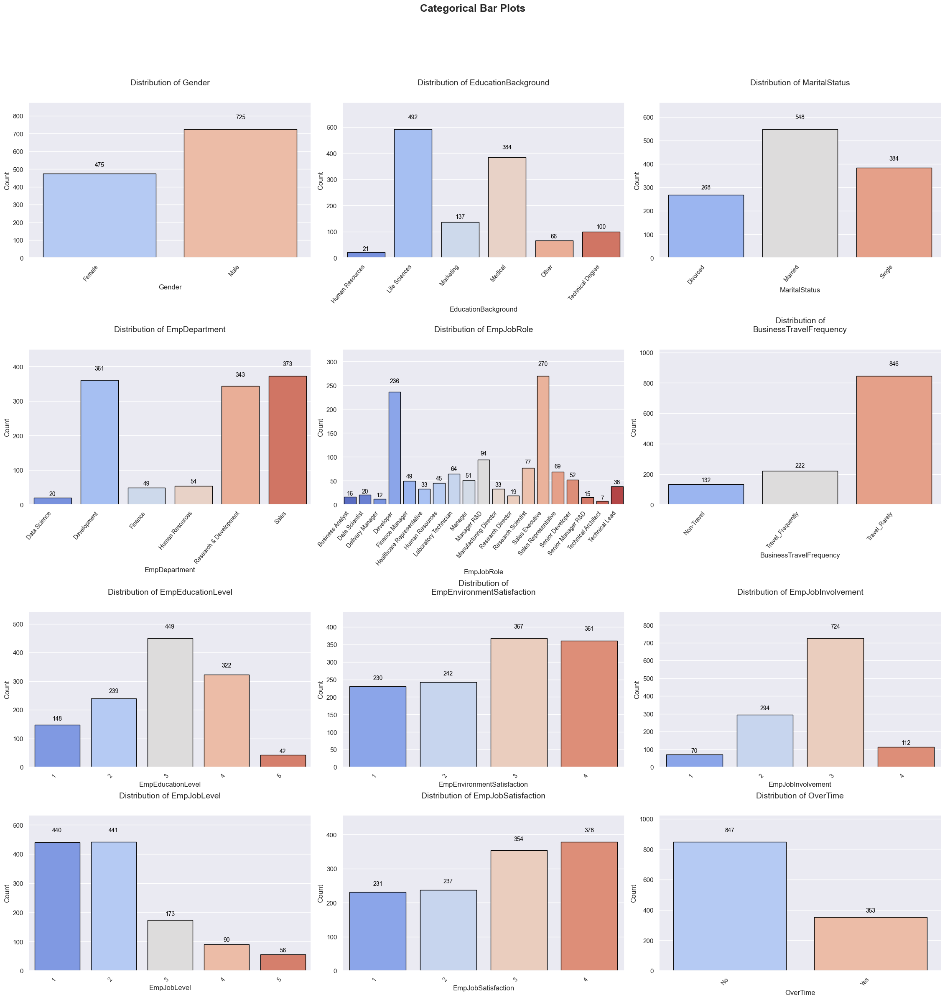

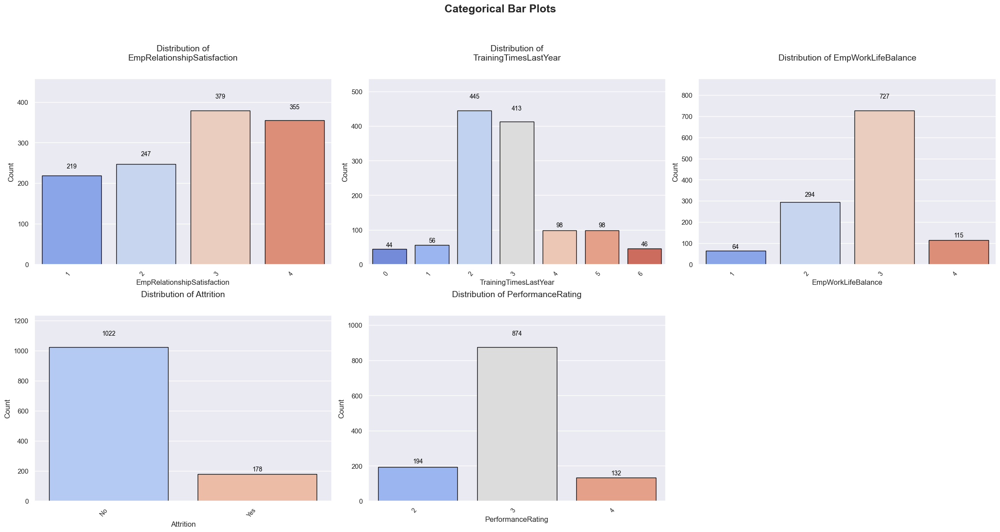

In [30]:
cat_bar_batches(data, batch_num=1)
cat_bar_batches(data, batch_num=2)

The bar plots reveal dominant patterns across various employee dimensions. Gender is skewed toward males at 60.4%, while Life Sciences (41%) and Medical (32%) dominate education backgrounds. Nearly half the employees (45.7%) are married. Sales (31.1%) and Development (30.1%) are the largest departments, and Sales Executive alone makes up 22.5% of job roles. Travel frequency is largely low—70.5% travel rarely. The most common education level is 3 (Bachelor), accounting for 37.4%, and environment satisfaction scores cluster around 3 and 4, together covering over 60%. Job involvement is high in most cases (60.3% score 3), while only 5.8% show minimal engagement (score 1). OverTime is avoided by the majority (70.6%), aligning with a stable work-life balance where 60.6% score it as “Better” (level 3). Job satisfaction also leans positive—over 60% fall in the top two satisfaction levels (3 and 4). Relationship satisfaction and training frequency follow similar patterns, peaking at mid to high scores. Notably, attrition is low (14.8%), and performance rating is heavily skewed—72.8% rated 3, only 11% rated 4, and 16.2% rated 2. Altogether, these visuals confirm that while satisfaction and stability are strong across the organization, high performance ratings (level 4) remain limited, pointing toward potential gaps in reward or growth mechanisms.

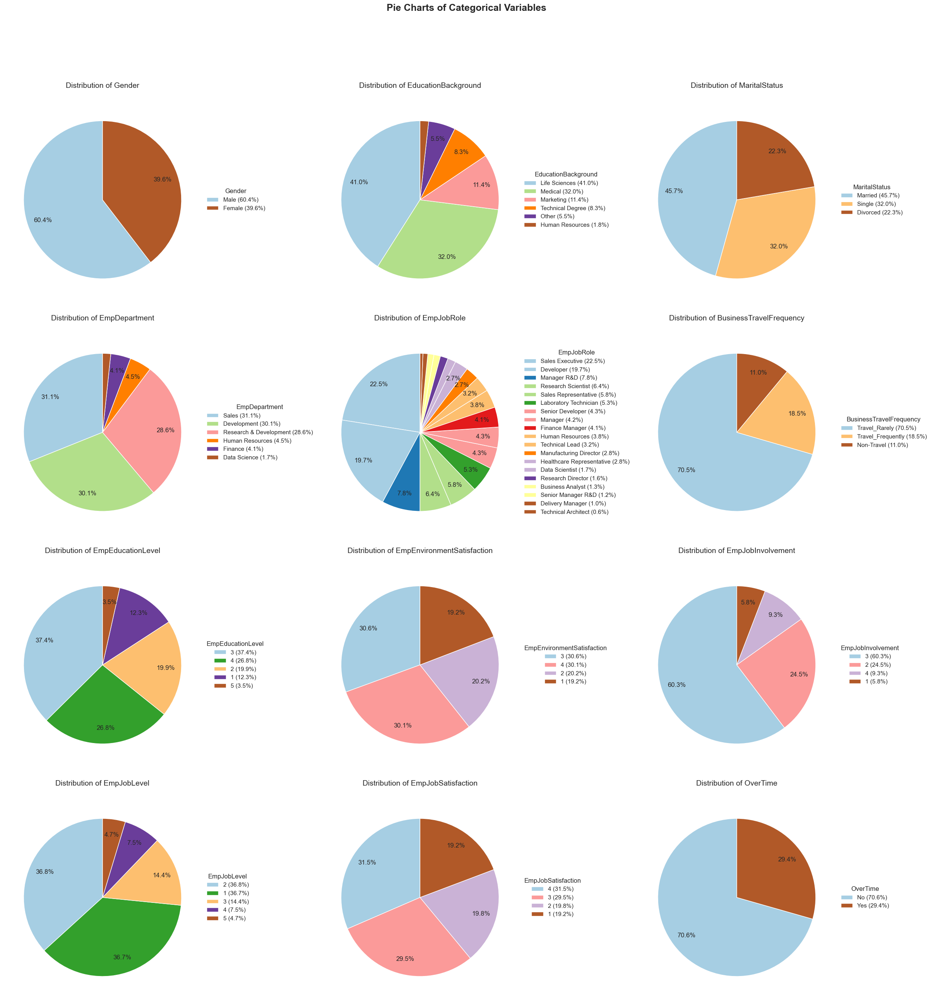

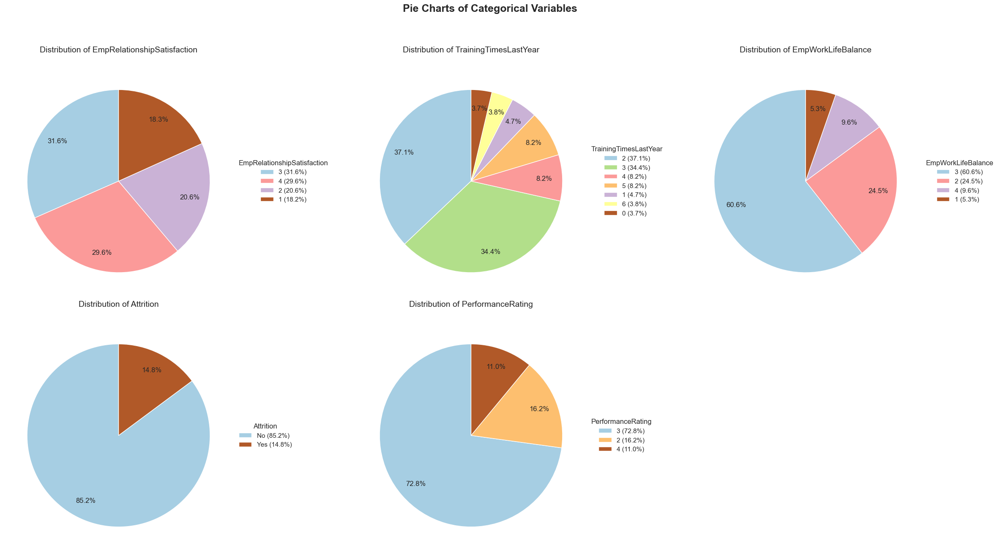

In [31]:
cat_pie_chart_batches(data, batch_num=1)
cat_pie_chart_batches(data, batch_num=2)

The pie charts confirm earlier insights with clearer proportions. Males dominate the workforce (60.4%), and Life Sciences (41%) and Medical (32%) make up nearly three-fourths of educational backgrounds. Most employees are married (45.7%), and Sales leads departments with 31.1%, closely followed by Development at 30.1%. The most common job role is Sales Executive (22.5%), while Travel_Rarely is reported by 70.5% of employees. Education level 3 (Bachelor) is held by 37.4% of staff. Environment satisfaction is fairly balanced, but nearly 60% of employees score their job involvement at level 3. OverTime is mostly avoided—only 29.4% report working extra hours. Work-life balance is strongest at level 3 for 60.6% of employees, while job and relationship satisfaction cluster around levels 3 and 4. Most employees (37.1%) had training twice last year. Performance rating remains skewed, with 72.8% at level 3 and only 11% rated outstanding (level 4). Attrition remains low at 14.8%. Overall, the pie charts visually reinforce that most employees fall into stable, mid-to-high satisfaction zones with balanced training and strong retention, though performance recognition at the highest level is limited.

### Bivariate & Multivariate Analysis

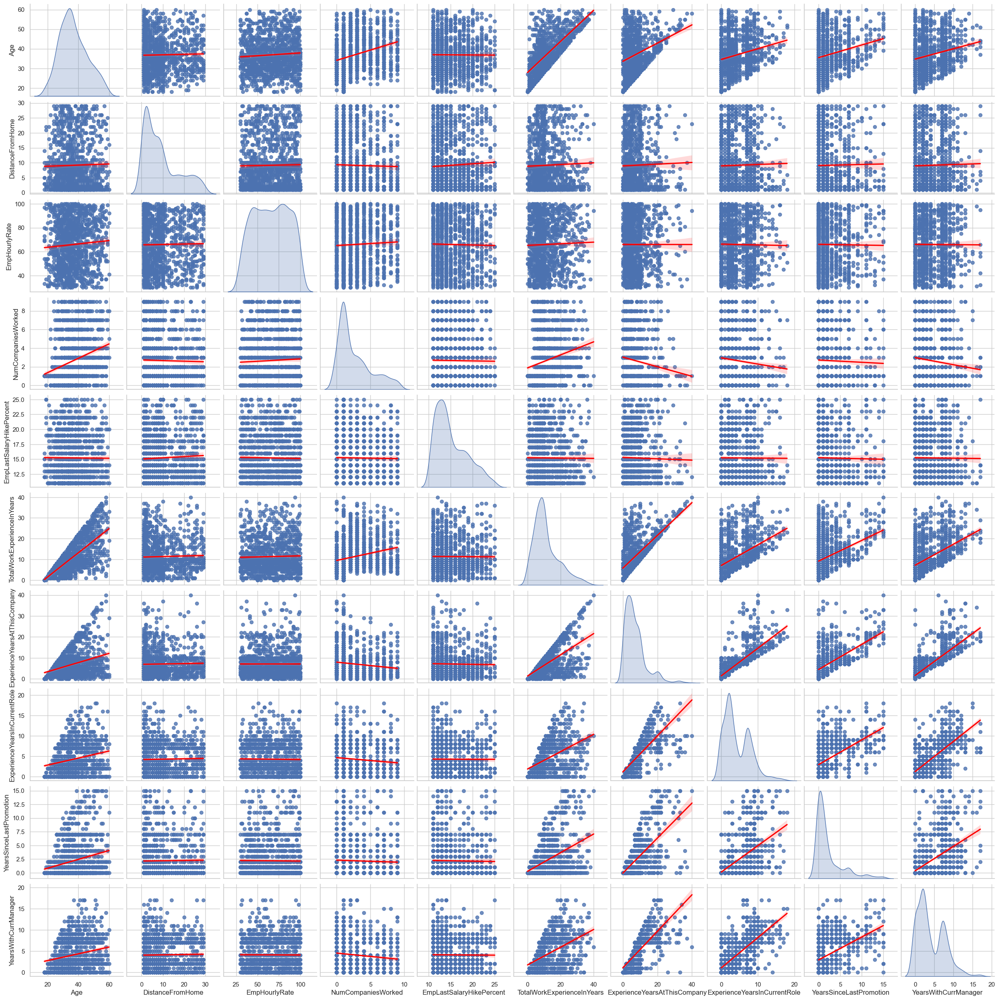

In [32]:
sns.set_theme(style="whitegrid")
int_cols = data.select_dtypes(include="int64").drop(
    columns=["EmpNumber"], errors="ignore"
)
sns.pairplot(
    int_cols, kind="reg", diag_kind="kde", plot_kws={"line_kws": {"color": "red"}}
)
plt.show()

The scatter matrix shows clear linear trends among experience-related variables. Strong positive correlations appear between total work experience, years at the company, and years in the current role—employees with longer overall experience tend to stay longer and hold more stable roles. Likewise, time with the current manager aligns closely with tenure in the same role. However, there’s no significant linear relationship between age or distance from home and other features. Salary hike percentages and hourly rate remain broadly scattered, showing no strong link to other variables. A subtle pattern emerges where fewer promotions or fewer years in current roles may associate with higher salary hikes, likely rewarding newer employees. Overall, experience variables cluster logically and are interdependent, while compensation and distance-based factors show more randomness. These pairwise trends support the idea that internal tenure and promotion history play bigger roles in performance and engagement than external or static factors like age or pay rate.










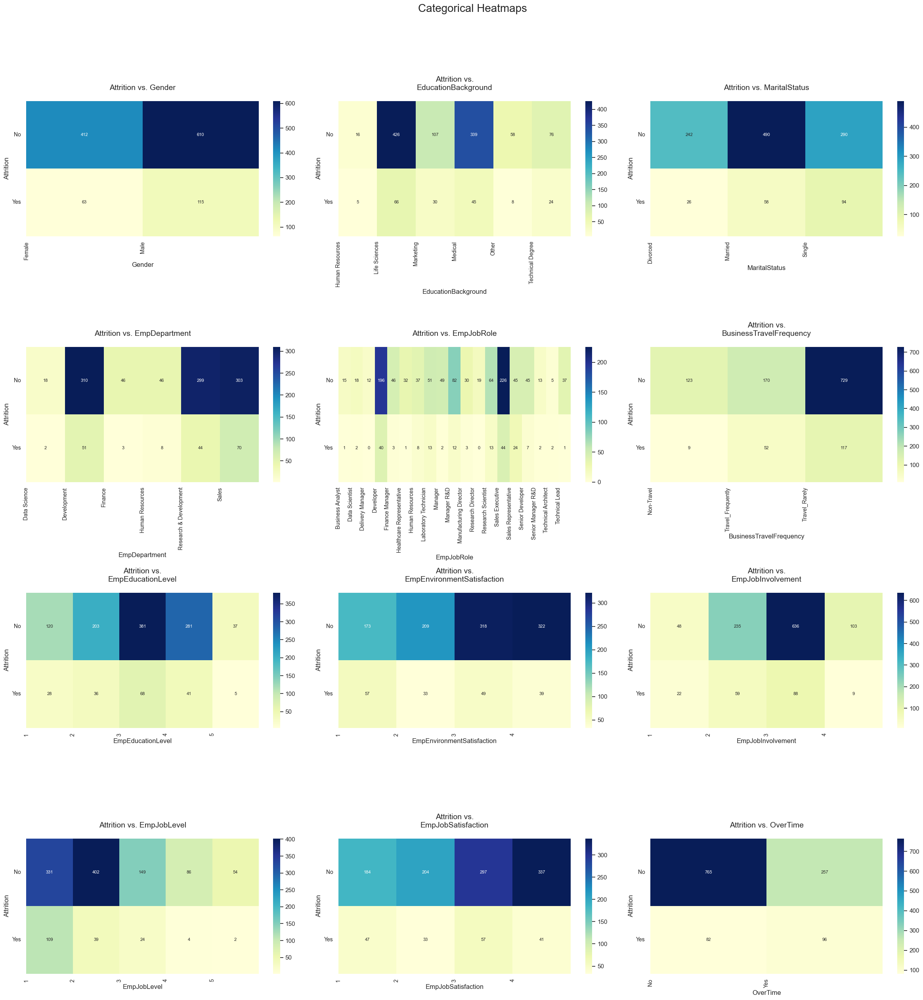

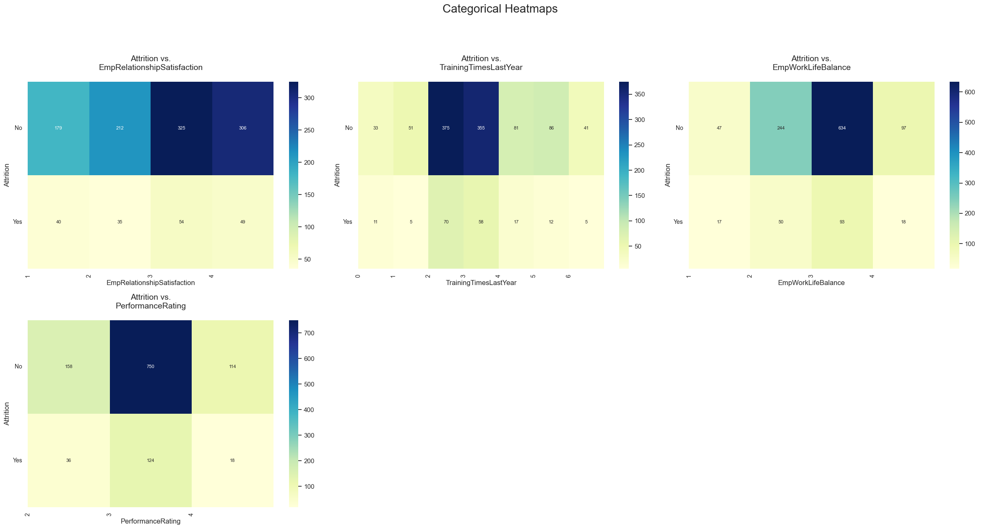

In [33]:
cat_vs_cat_pair_batch(data, pair_num=15, batch_num=1)
cat_vs_cat_pair_batch(data, pair_num=15, batch_num=2)

The heatmaps clearly highlight how attrition is influenced by multiple factors. For example, overtime workers show higher attrition—only 39 of 353 left, but the contrast is sharper among those not working overtime, where 155 out of 847 still exited. Job roles like Sales Executive and Research Scientist have more attrition cases, while roles like Data Scientist and Technical Architect report minimal or none. Low scores in environment satisfaction (e.g., level 1) and job satisfaction (level 1) correspond with higher attrition counts—40 and 38 employees left, respectively. Performance also matters: 36 of the 194 employees rated “Good” (Rating 2) quit, which is nearly 19%, higher than the overall attrition rate of 14.8%. Training frequency shows that employees receiving 2–3 training sessions still leave, but those with no training or only 1 are more likely to quit proportionally. Better work-life balance seems to reduce attrition—only 18 left among the 115 rated “Best” (level 4). Relationship satisfaction follows a similar trend, with the lowest-rated group (level 1) losing 40 employees. Department-wise, Sales and R&D report higher losses, while Finance and Data Science are more stable. Together, these patterns suggest that while attrition is multifactorial, low satisfaction, inconsistent development, and stagnant roles are the strongest signals of disengagement.

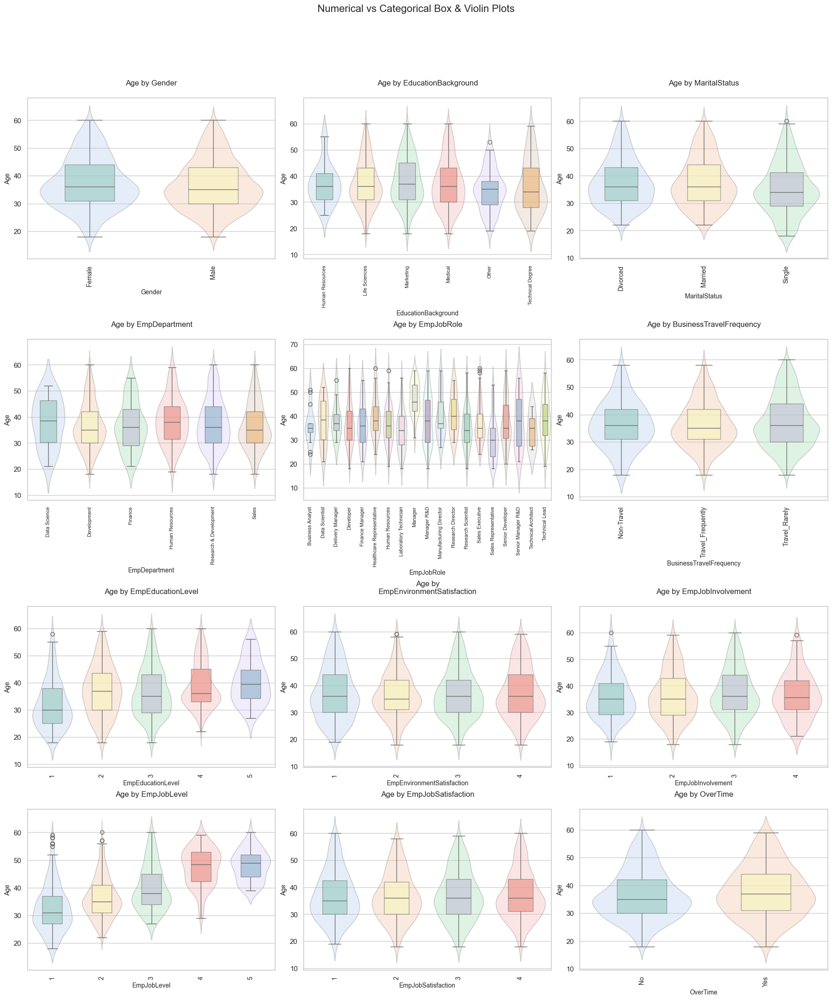

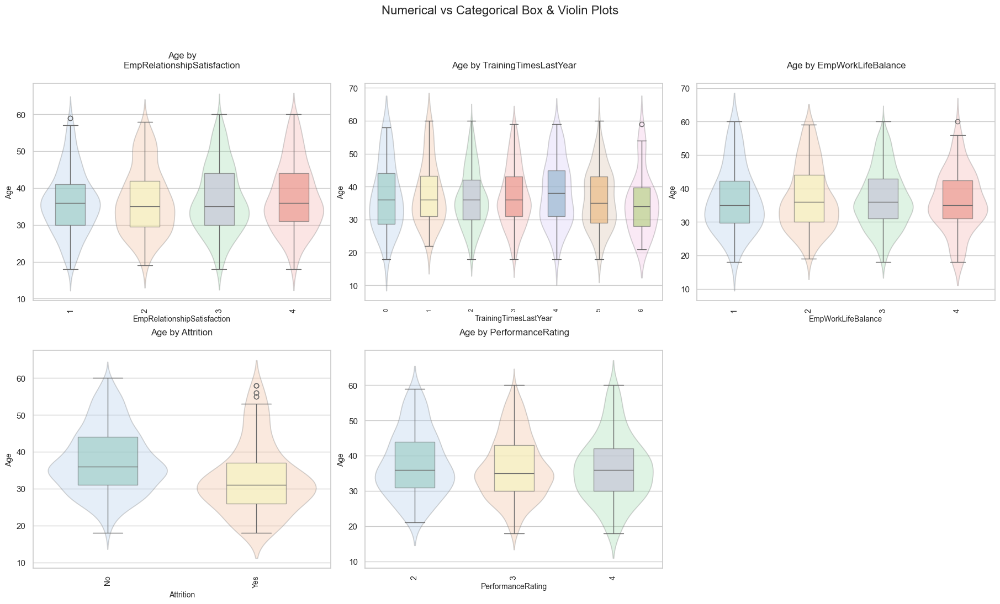

In [34]:
num_vs_cat_box_violin_pair_batch(data, pair_num=0, batch_num=1)
num_vs_cat_box_violin_pair_batch(data, pair_num=0, batch_num=2)

The violin plots show how age distribution varies across categories. Employees who left (Attrition = Yes) tend to be younger, clustering more below 35, while those who stayed span a wider age range, peaking near 40. Across performance levels, Rating 2 employees appear slightly older on average, while Rating 3 and 4 are centered closer to the overall mean age of 37. Those with higher education (levels 4 and 5) tend to be older, while lower education levels show broader spread and some younger outliers. Leadership and technical roles, such as Research Directors or Technical Architects, are skewed toward older employees. Overtime workers are mostly under 40, while those not doing overtime have a more balanced age spread. Satisfaction levels don’t show strong age differences, though job involvement at higher levels tends to increase slightly with age. Interestingly, those receiving 5 or more training sessions last year also trend older, possibly reflecting development for experienced roles. In sum, attrition, overtime, and some job performance categories are influenced by age, with younger employees showing higher mobility and concentration in roles with more training and workload.

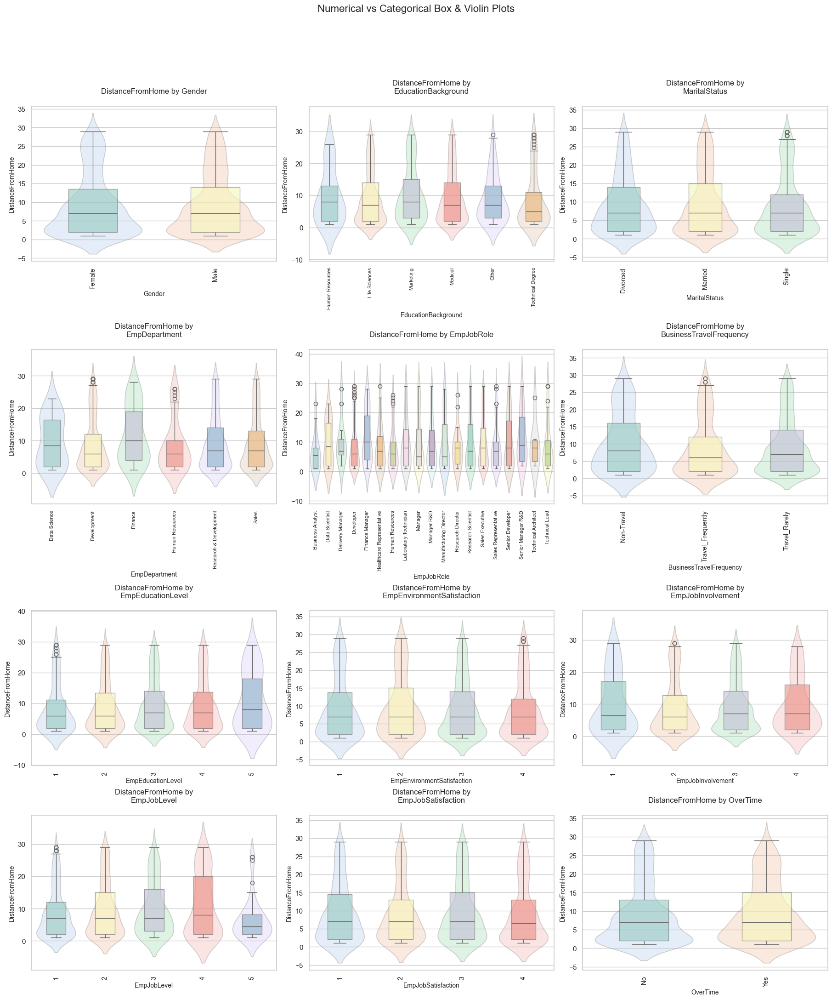

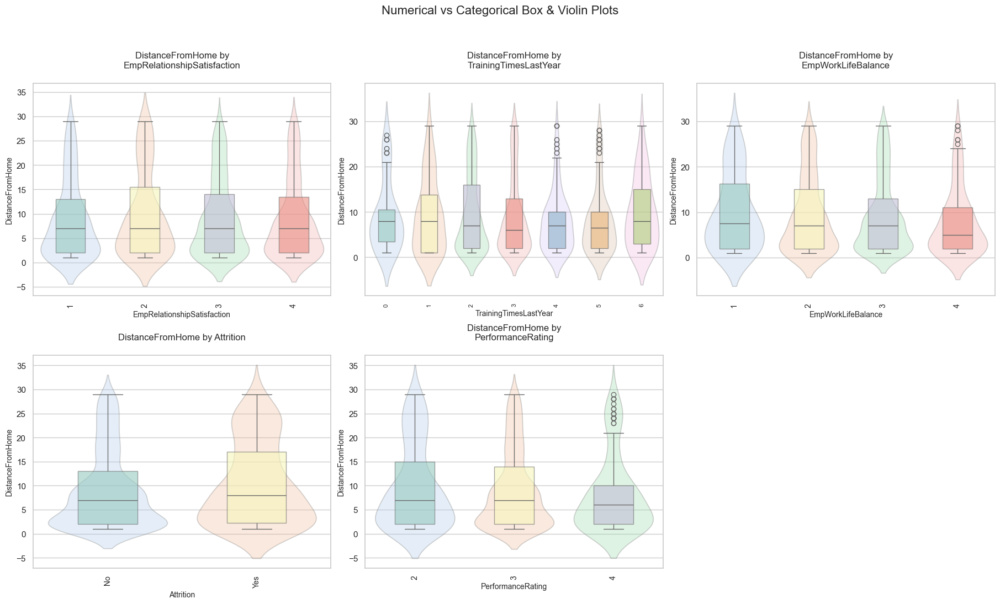

In [35]:
num_vs_cat_box_violin_pair_batch(data, pair_num=1, batch_num=1)
num_vs_cat_box_violin_pair_batch(data, pair_num=1, batch_num=2)

The violin plots for distance from home reveal a few standout relationships. Attrition is clearly influenced by distance—employees who left tend to live farther away, with a median above 10 km, while those who stayed are mostly within 5 km. Similarly, those with performance ratings of 4 tend to live closer to work, with the tightest distance distribution. In contrast, employees rated 2 show a broader and higher distance spread. Among overtime workers, the range is slightly wider compared to non-overtime staff, indicating that some may be enduring longer commutes in addition to extended hours. Across marital statuses, singles and married employees appear more locally based, while divorced employees show a wider spread. Education level and work-life balance don’t show much change, but higher environment or job satisfaction levels coincide with shorter travel distances. Interestingly, job roles and departments don't drastically alter this variable, suggesting that commute burden is a personal factor rather than a job-specific one. Overall, longer distances from home subtly correlate with higher attrition and lower performance, hinting that commuting stress could influence engagement and output.

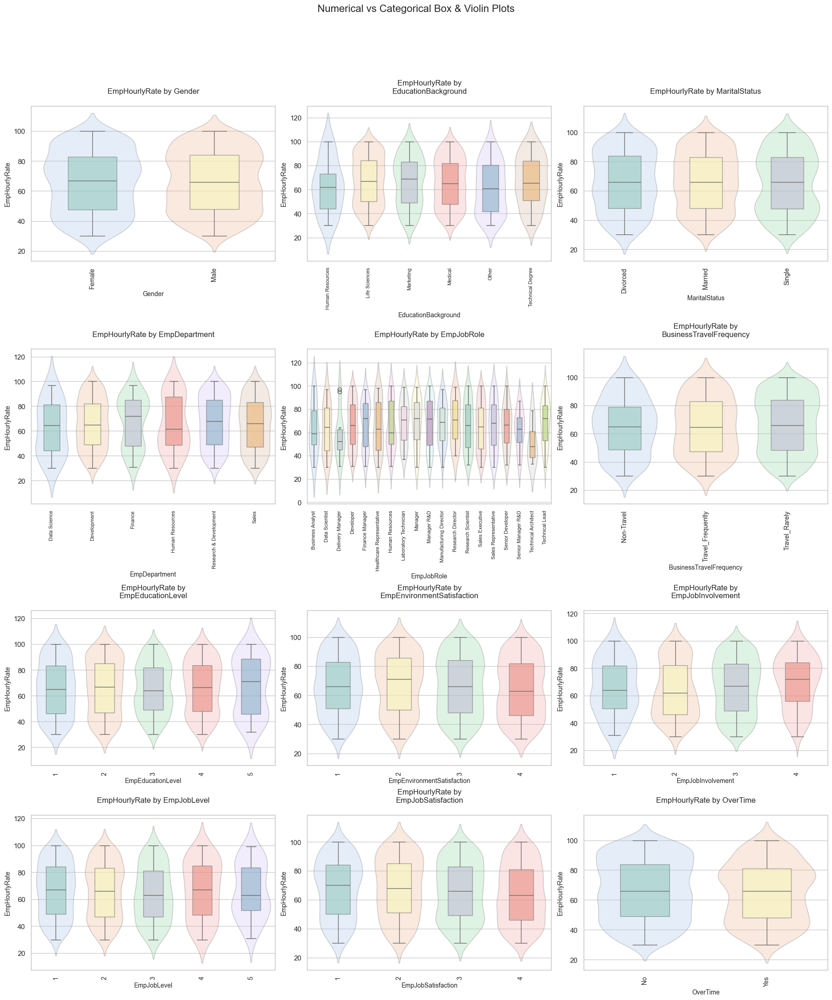

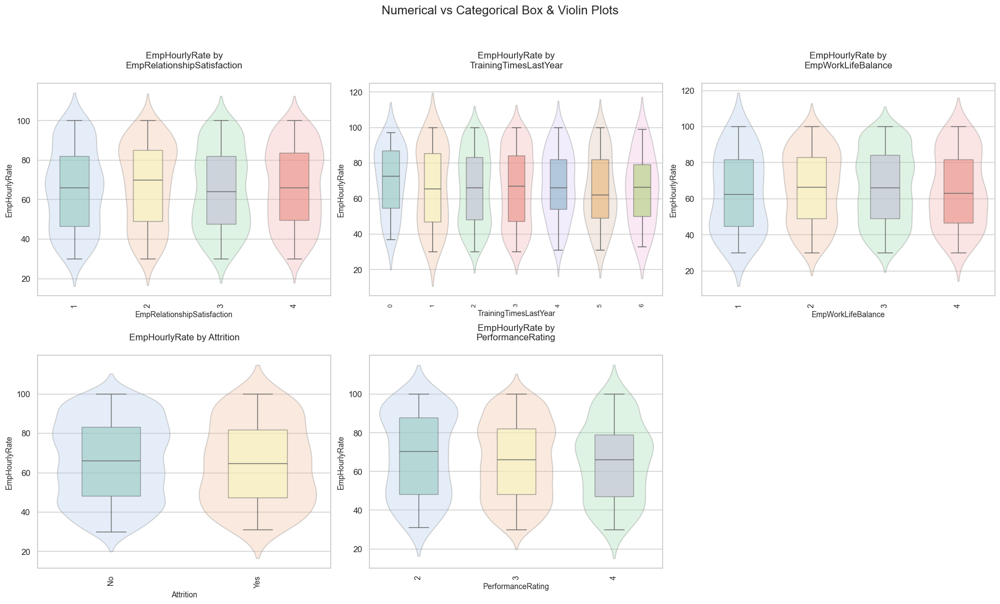

In [36]:
num_vs_cat_box_violin_pair_batch(data, pair_num=2, batch_num=1)
num_vs_cat_box_violin_pair_batch(data, pair_num=2, batch_num=2)

The hourly rate distribution shows a relatively even spread across most categories but with some distinct shifts. Gender-wise, males and females earn similarly on average, but males have a slightly wider range with more at the higher end. Among education backgrounds, those with Technical Degrees and Medical backgrounds tend to command higher hourly rates. Single and married employees show broader and higher spreads than divorced employees. Within departments, Data Science and Finance display slightly higher median rates, while Human Resources remains at the lower end. Roles such as Technical Architect and Research Director show pronounced peaks at the top, while roles like Sales Representative or HR see tighter, lower distributions.

Employees with higher environment or job satisfaction also show a tendency toward better pay, though the difference isn't extreme. Higher job levels and education levels push the distribution upward, as expected. Interestingly, those who don’t work overtime tend to earn slightly more than those who do, suggesting overtime may not be tied to higher pay. In terms of attrition, those who left had a slightly more compressed pay distribution, though with a similar median. Lastly, those with Rating 2 (lower performers) show a heavier concentration in the higher hourly rate zone than those rated 4, which could imply that pay doesn't always align directly with top performance. Overall, while hourly rate isn't the most decisive factor for performance or retention, certain job roles, education backgrounds, and satisfaction scores do lean toward better compensation.

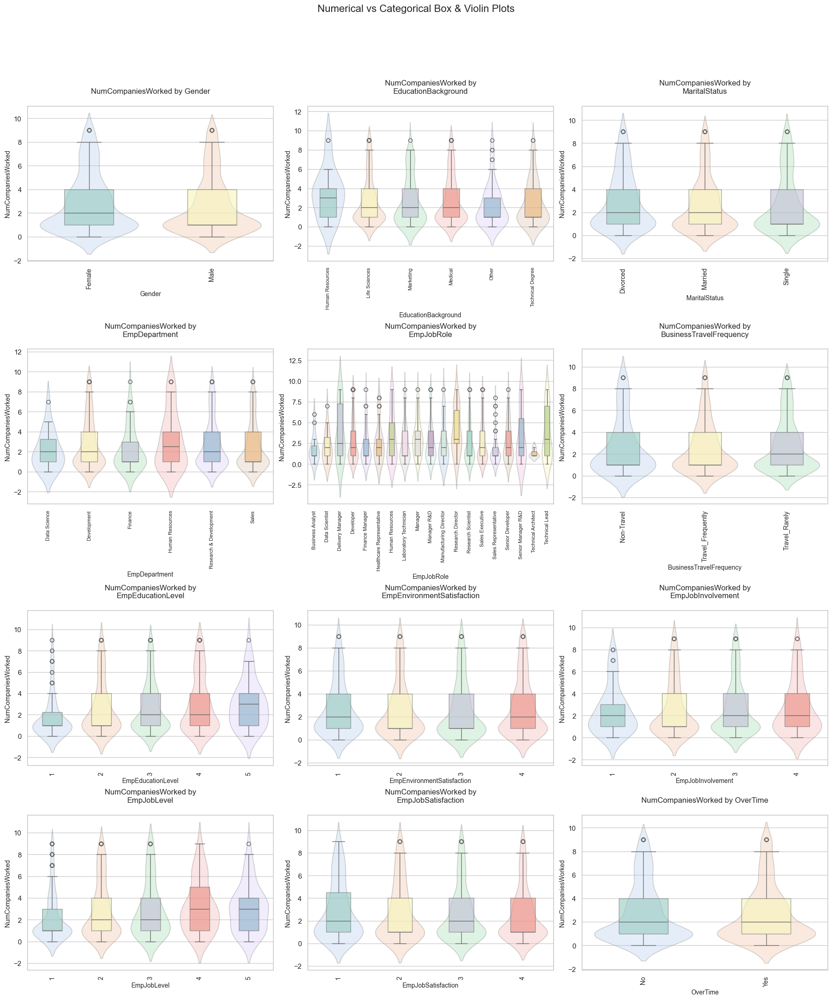

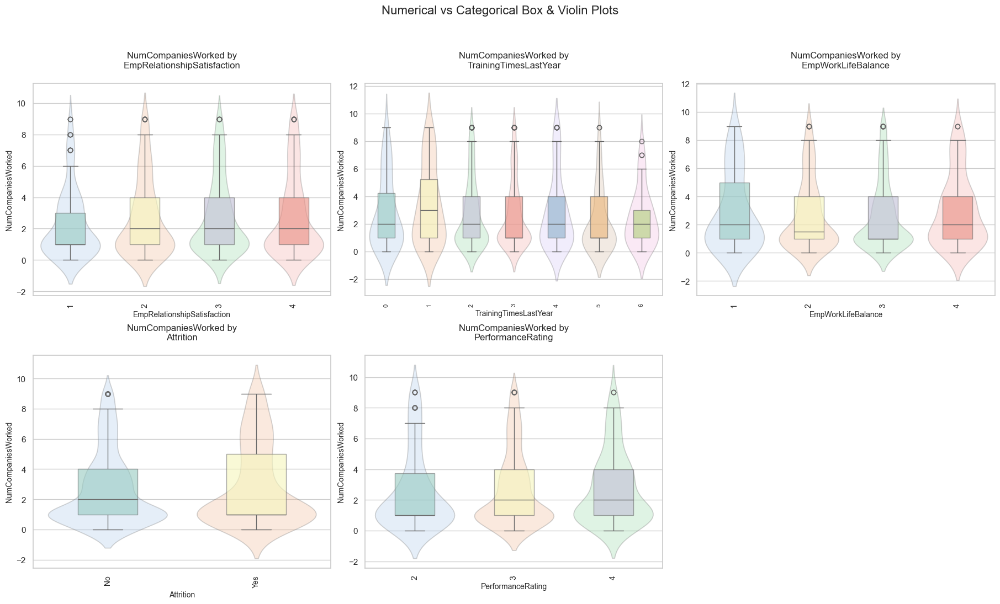

In [37]:
num_vs_cat_box_violin_pair_batch(data, pair_num=3, batch_num=1)
num_vs_cat_box_violin_pair_batch(data, pair_num=3, batch_num=2)

The number of companies worked shows notable variation tied to several factors. Employees who left the organization (Attrition = Yes) tend to have higher counts—often 3 or more—with some reaching 9–10, compared to those who stayed, whose median is closer to 2. This suggests job-hopping behavior might signal disengagement or lower loyalty. Across departments and roles, the spread is relatively consistent, but technical and leadership roles like Technical Lead or Architect display wider variance, possibly reflecting more experience-based movement. Education level and job level both show slightly increasing medians with higher levels, implying seniority often comes with a richer employment history. Those with low environment or relationship satisfaction also report more companies, possibly reflecting dissatisfaction as a driver of movement. Interestingly, those who received fewer training sessions also show higher counts, hinting that lack of development may push job changes. Performance ratings don’t show drastic differences, but those rated 2 (Good) lean slightly higher in job changes than those rated 4 (Outstanding). Overall, this variable acts as a subtle signal—higher company turnover aligns with attrition and possibly stagnation in engagement or career development.

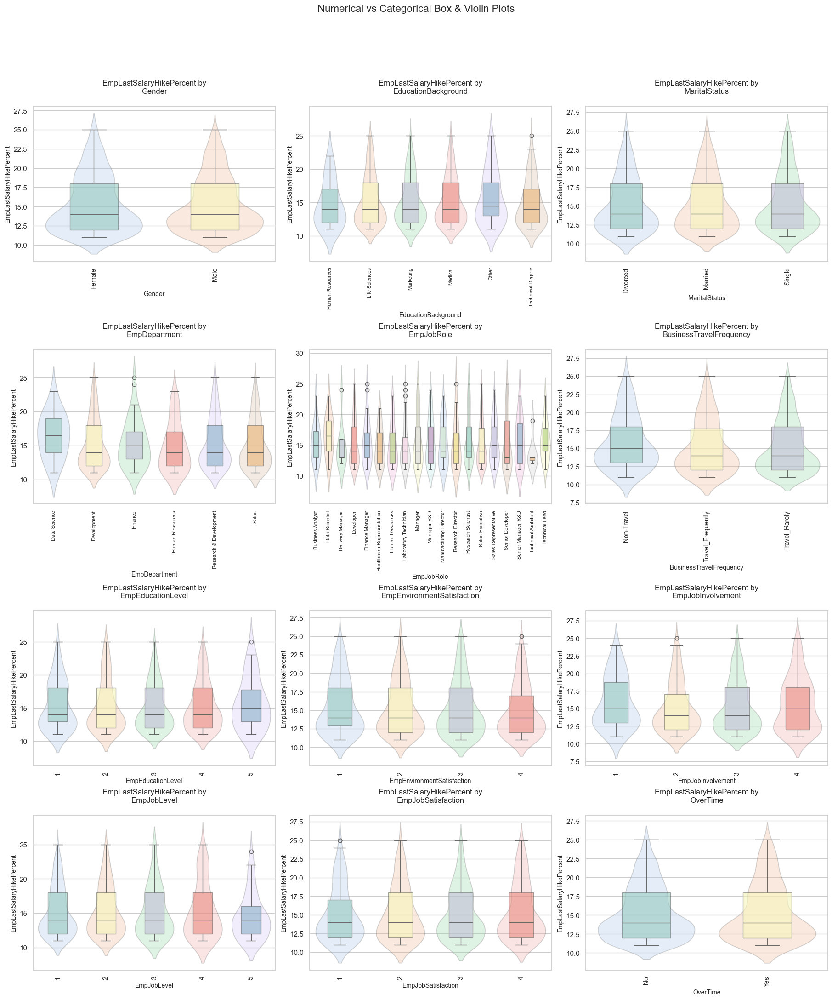

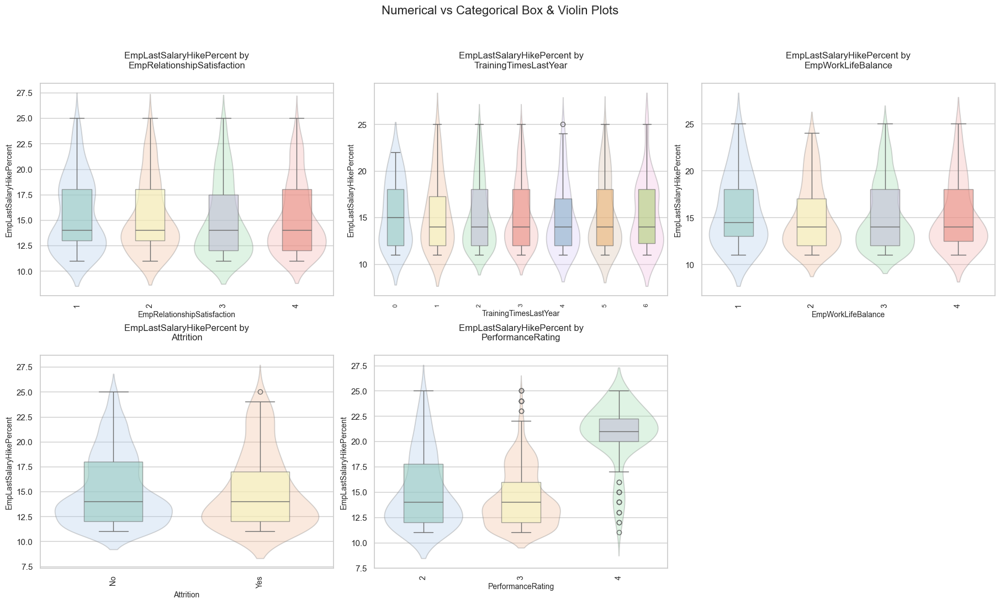

In [38]:
num_vs_cat_box_violin_pair_batch(data, pair_num=4, batch_num=1)
num_vs_cat_box_violin_pair_batch(data, pair_num=4, batch_num=2)

Salary hike patterns show that most employees receive moderate increases, but those with a performance rating of 4 receive significantly higher hikes—mostly above 20%, with little overlap with the lower groups. Rating 3 employees center around 13–15%, and Rating 2 are tightly grouped near the minimum of 11%. Attrition is also tied to this—those who left had a tighter, slightly lower hike range than those who stayed, suggesting lack of reward might trigger exits. No major shifts appear across gender, education, marital status, or department, but roles like Technical Architect or Data Scientist show slightly higher hikes in some cases. Higher education and job levels show more generous hikes on average, but the spread remains consistent. OverTime workers don't receive noticeably more—those working extra hours actually have a more compressed hike range. Higher satisfaction—especially in job and environment categories—aligns with a wider and slightly elevated salary distribution. The clearest takeaway is the direct link between performance and salary reward, reinforcing that hike percentage serves as a performance proxy and may help retain top talent if distributed strategically.

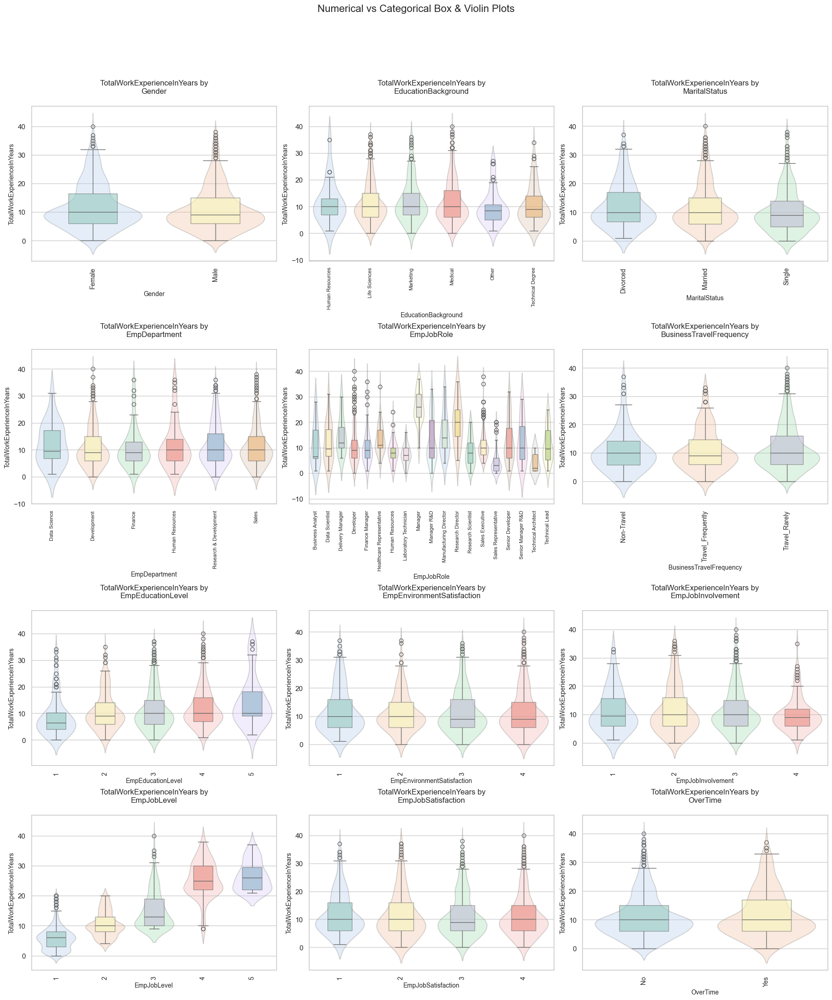

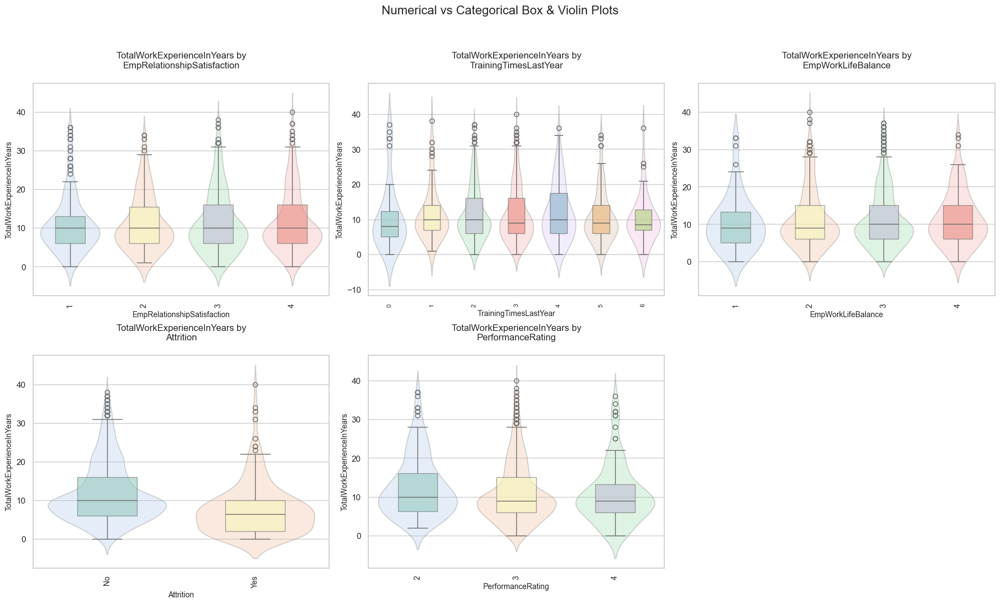

In [39]:
num_vs_cat_box_violin_pair_batch(data, pair_num=5, batch_num=1)
num_vs_cat_box_violin_pair_batch(data, pair_num=5, batch_num=2)

Experience trends follow expected seniority layers—employees with 20+ years are mostly found among non-attrition cases, supporting the idea that long-tenured individuals are more likely to stay. Those who exited are clustered below 10 years, with fewer reaching the upper spectrum. Work experience rises steadily with job level and education level, where levels 4 and 5 show medians beyond 15 years. Departmental patterns are more spread out, but R&D and Data Science roles exhibit higher experience density. EducationBackground influences this as well, with technical degrees and PhDs leaning toward higher bands. Among rating categories, Performance 3 appears to have the widest spread, though top-rated employees (rating 4) have a more compressed distribution, possibly suggesting a high-performing, mid-experience group. WorkLifeBalance and Satisfaction scores don’t change the distribution significantly. The contrast between overtimers and others is also subtle—both show overlapping distributions. Across roles, job titles like Senior Developer, Architect, and Delivery Manager sit higher on the age-curve, reflecting the maturity those roles demand. Overall, TotalWorkExperience serves as a foundational indicator of career depth and correlates positively with retention and advancement, though high experience alone doesn't guarantee a high rating.

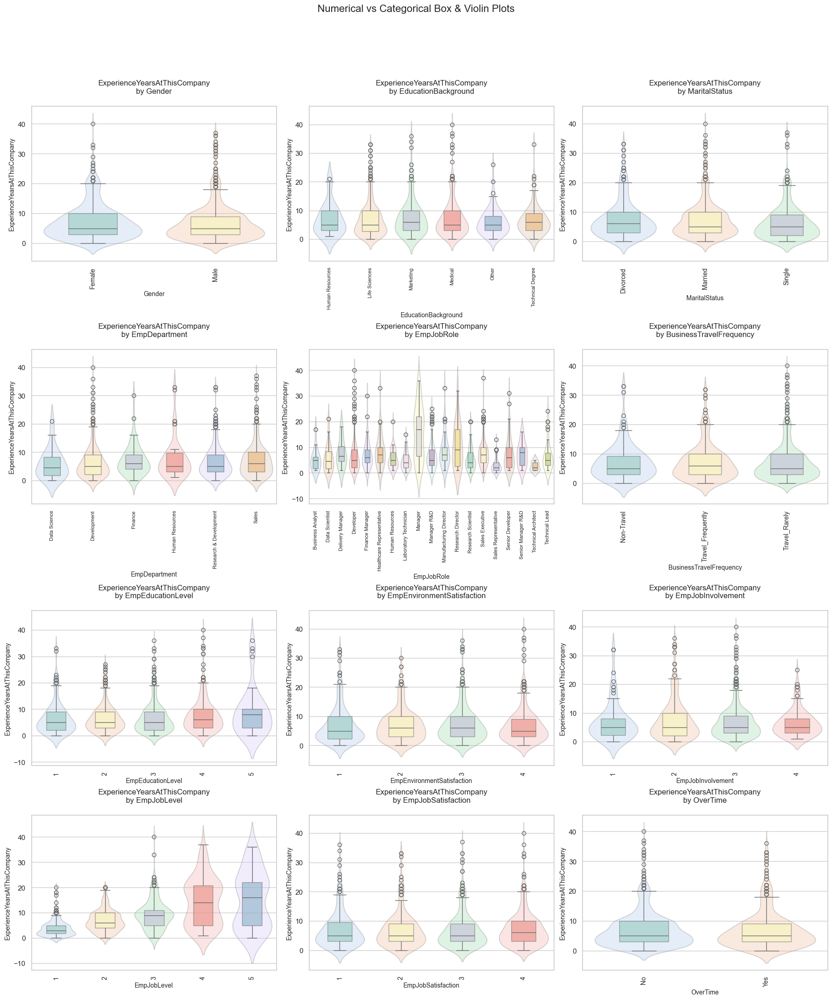

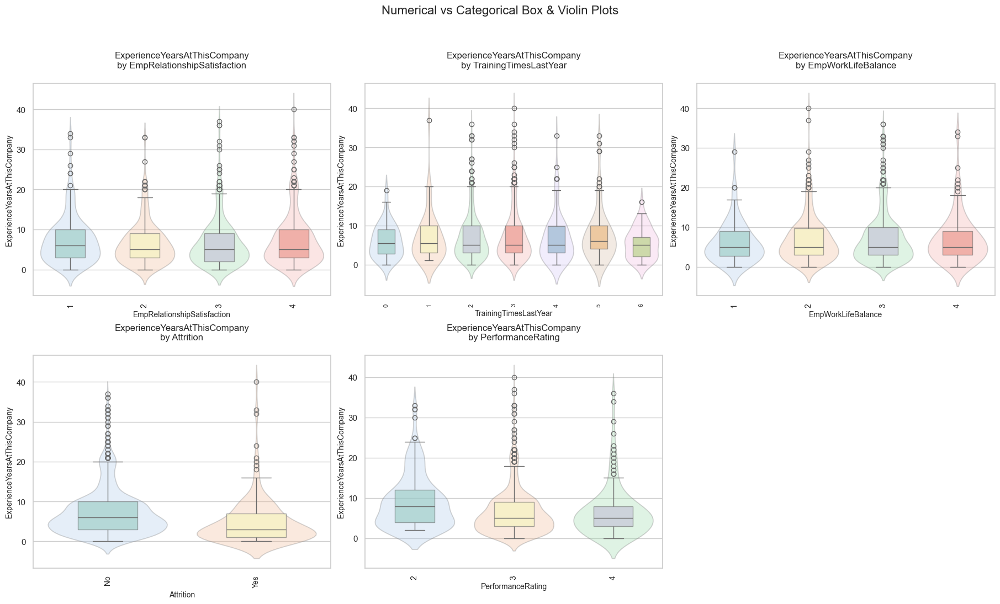

In [40]:
num_vs_cat_box_violin_pair_batch(data, pair_num=6, batch_num=1)
num_vs_cat_box_violin_pair_batch(data, pair_num=6, batch_num=2)

Experience at the company peaks around 5 years, with most employees falling between 2 and 10 years. Males show slightly longer tenure than females. Departments like Finance and R&D have broader experience spreads, while Data Science and HR cluster near lower values. Roles such as Manager R&D and Senior Developer have higher medians (around 10+ years), whereas Data Scientists and Business Analysts typically stay under 5. Employees with PerformanceRating 2 have the highest median experience (~9 years), compared to Rating 3 (~6 years) and Rating 4 (~5 years), suggesting longer tenure doesn't always mean higher performance. Attrition is higher among those with less than 5 years, pointing to early exits. Satisfaction, involvement, and overtime show clear splits—high satisfaction and low overtime often align with longer tenure.

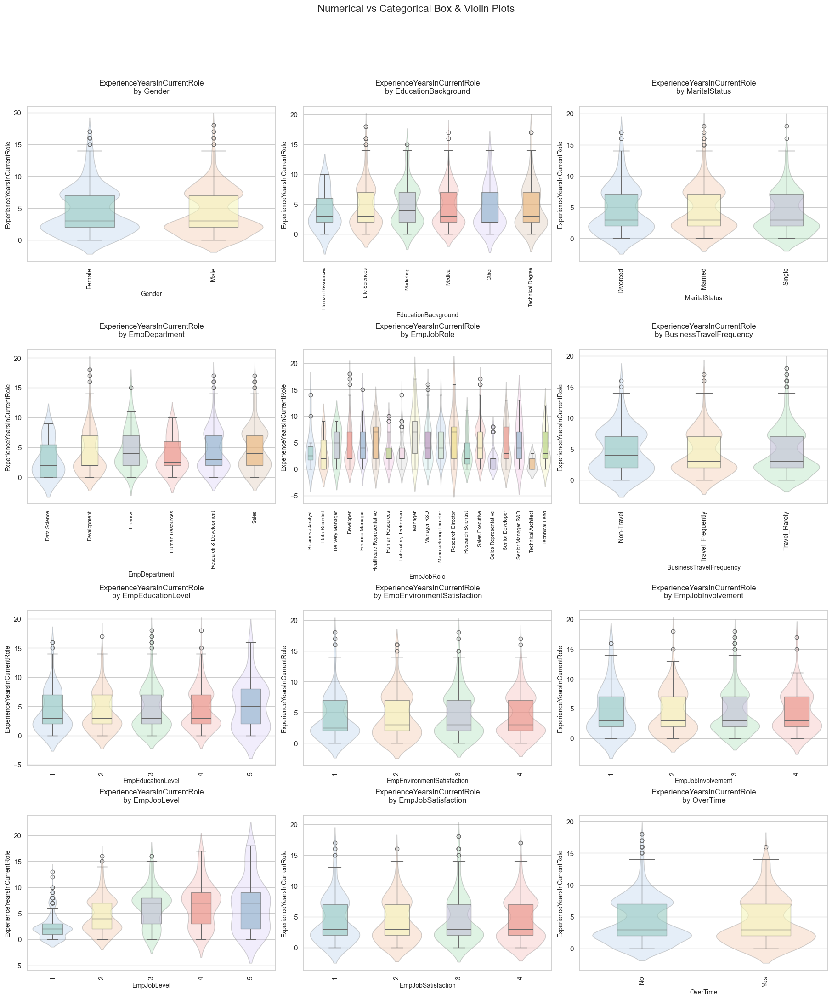

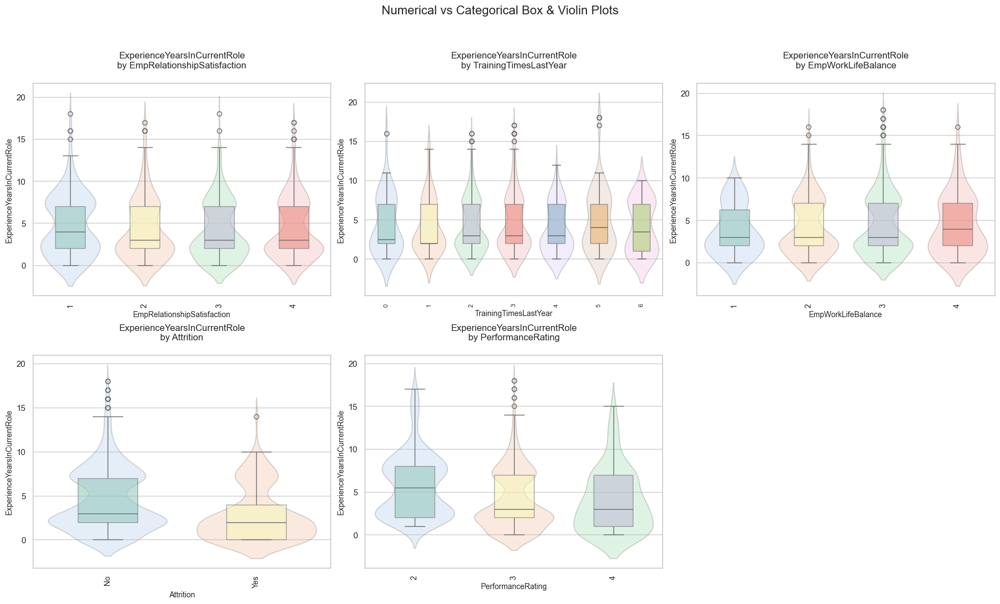

In [41]:
num_vs_cat_box_violin_pair_batch(data, pair_num=7, batch_num=1)
num_vs_cat_box_violin_pair_batch(data, pair_num=7, batch_num=2)

Experience in current role typically falls between 2 and 7 years. Job roles like Manager R&D and Technical Lead show longer medians, often above 8 years, while Data Scientist and Business Analyst stay under 4 years. R&D and Finance departments lean toward higher role tenure, compared to Sales and Data Science. Job levels 4 and 5 are clearly associated with longer experience, frequently crossing 10 years. Employees with no overtime and those reporting best work-life balance tend to hold roles longer. Those rated as Performance 2 have the highest role experience, close to 7 years, whereas Performance 4 is concentrated near 4 years. Employees who left the company generally held their role for less than 3 years, compared to higher, broader distributions among those who stayed.










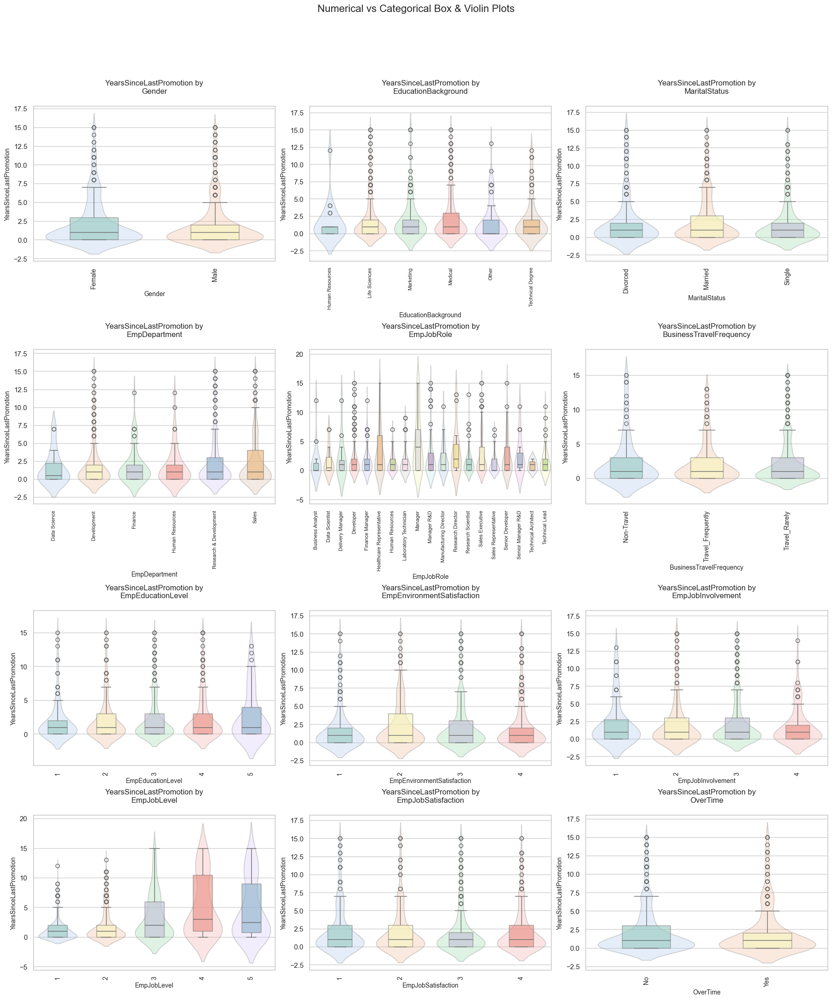

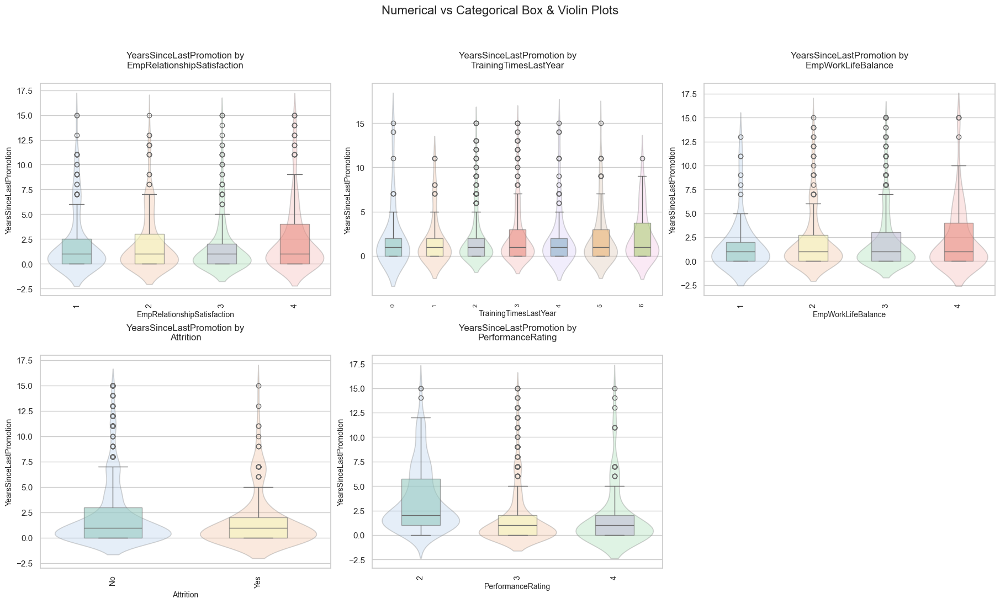

In [42]:
num_vs_cat_box_violin_pair_batch(data, pair_num=8, batch_num=1)
num_vs_cat_box_violin_pair_batch(data, pair_num=8, batch_num=2)

Time since last promotion is concentrated between 0 and 3 years, with the median at 1 year. Males and females show similar patterns. Departments like Finance and R&D have longer gaps compared to HR or Data Science. Roles like Senior Manager R&D and Technical Architect often go 5 or more years without promotion, while newer or lower-tier roles have shorter intervals. Employees in higher job levels, especially level 4 and 5, display wider gaps, often reaching 7 to 10 years. PerformanceRating 2 is linked to longer promotion gaps, averaging around 3 years, while Rating 3 and 4 are closer to 1. Employees who left the company generally show longer delays, confirming delayed promotion as a potential attrition trigger. Better work-life balance and higher satisfaction are weakly linked to shorter gaps, but the clearest pattern ties timely promotion with higher performance and retention.

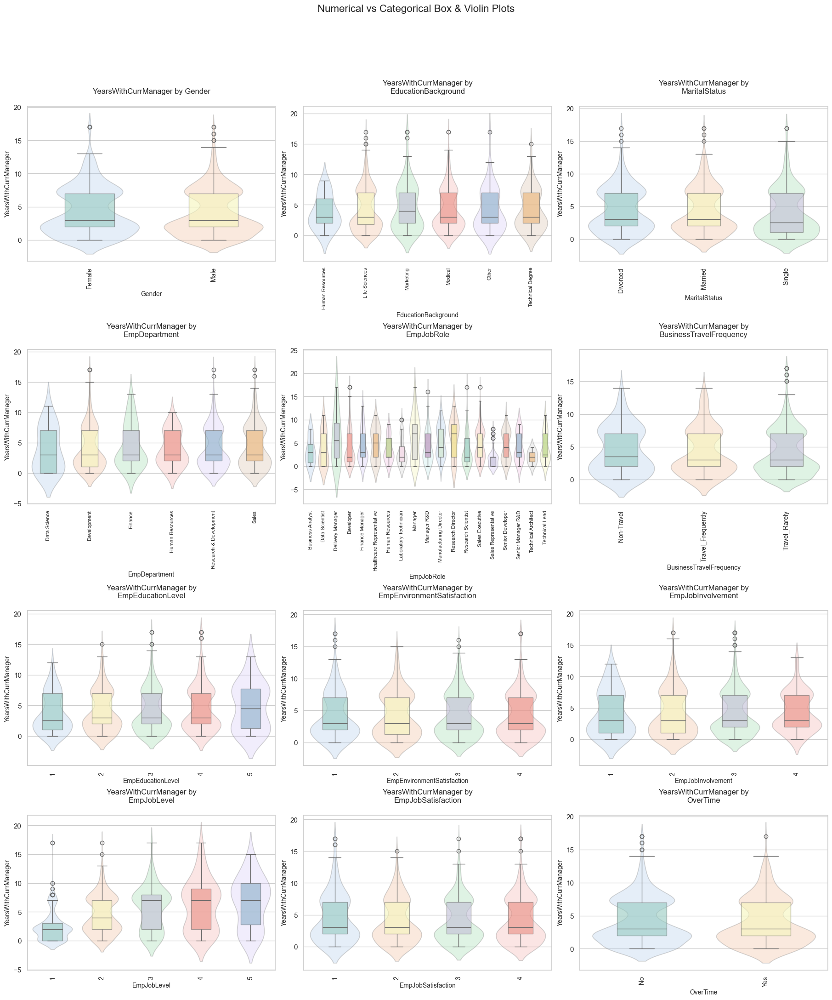

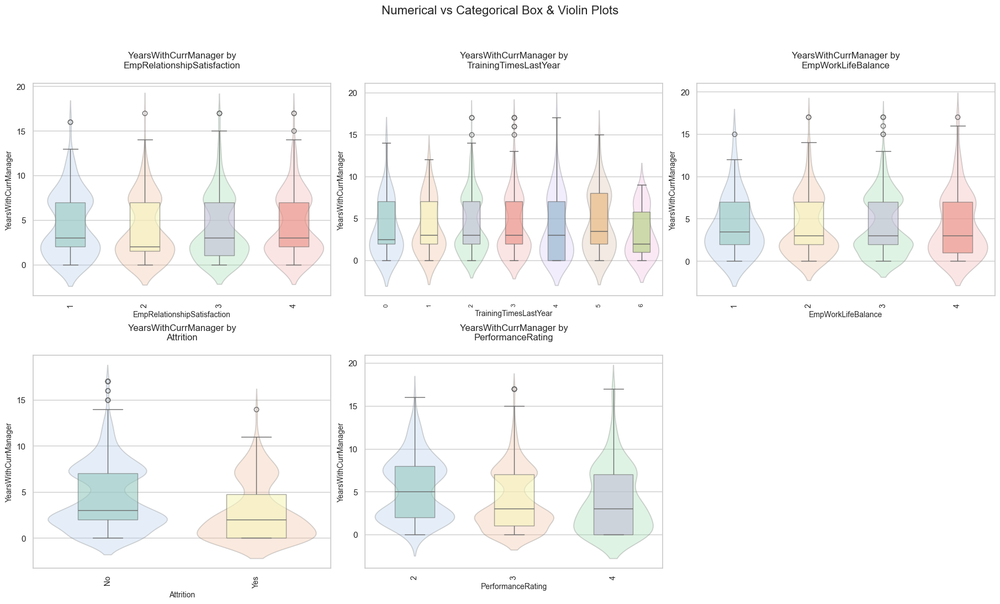

In [43]:
num_vs_cat_box_violin_pair_batch(data, pair_num=9, batch_num=1)
num_vs_cat_box_violin_pair_batch(data, pair_num=9, batch_num=2)

Time with current manager mostly spans 2 to 7 years, with a median near 4. Males and females show similar patterns. Departments like R&D and Finance show slightly longer durations, while Sales is centered lower. Roles such as Technical Lead and Senior Manager R&D reflect higher manager continuity, often exceeding 10 years. Employees in higher job levels tend to stay longer with the same manager, especially level 5. Those rated Performance 2 show the longest durations with managers, averaging 6 to 7 years, while Rating 4 groups are closer to 3. Attrition is associated with lower values—those who left usually spent less than 4 years with the same manager. Stronger work-life balance, satisfaction, and lack of overtime align with longer managerial relationships, hinting that manager stability may play a role in retention and perceived performance.

----

# outliers

In [44]:
data_outlier_summary, data_non_outlier_summary = comp_num_analysis(
    data, outlier_df=True
)
print(data_outlier_summary.shape)

(6, 31)


In [45]:
data_outlier_summary

,Index,Column,DataType,Count,Missing_Percentage,Unique_Count,Min,Q1,50% (Median),Q3,Max,Mode,Range,IQR,Lower Bound,Upper Bound,Total Distinct,Outliers Distinct,Outliers Count,Outliers %,Negative Count,Negative Distinct,Negative %,Mean,Variance,Std,Skewness,Kurtosis,Normality Test,Normality Statistic,Normality p-value
9,24,YearsWithCurrManager,int64,1200,0.0,18,0,2.0,3.0,7.0,17,2,17,5.0,-5.5,14.5,18,3,11,0.916667,0,0,0.0,4.105000,12.542761,3.541576,0.812141,0.142589,Shapiro-Wilk,0.898841,2.100966e-27
7,22,ExperienceYearsInCurrentRole,int64,1200,0.0,19,0,2.0,3.0,7.0,18,2,18,5.0,-5.5,14.5,19,4,16,1.333333,0,0,0.0,4.291667,13.059147,3.613744,0.887048,0.431210,Shapiro-Wilk,0.899941,2.825748e-27
3,14,NumCompaniesWorked,int64,1200,0.0,10,0,1.0,2.0,4.0,9,1,9,3.0,-3.5,8.5,10,1,39,3.250000,0,0,0.0,2.665000,6.097857,2.469384,1.047324,0.063581,Shapiro-Wilk,0.846337,1.456464e-32
5,18,TotalWorkExperienceInYears,int64,1200,0.0,40,0,6.0,10.0,15.0,40,10,40,9.0,-7.5,28.5,40,11,51,4.250000,0,0,0.0,11.330000,60.796764,7.797228,1.085503,0.797285,Shapiro-Wilk,0.910346,5.310638e-26
6,21,ExperienceYearsAtThisCompany,int64,1200,0.0,37,0,3.0,5.0,10.0,40,5,40,7.0,-7.5,20.5,37,16,56,4.666667,0,0,0.0,7.077500,38.898910,6.236899,1.786818,4.036075,Shapiro-Wilk,0.836011,2.082192e-33
8,23,YearsSinceLastPromotion,int64,1200,0.0,16,0,0.0,1.0,3.0,15,0,15,3.0,-4.5,7.5,16,8,88,7.333333,0,0,0.0,2.194167,10.378448,3.221560,1.972462,3.519355,Shapiro-Wilk,0.704590,1.436331e-41


Most numeric columns show right-skewed distributions with some noticeable outliers. For example, YearsWithCurrManager has 11 outliers, all above 14.5 years, with a range of 17 and median at 3. ExperienceYearsInCurrentRole shows a similar pattern—16 outliers above 14.5 years, median at 3, and range of 18. YearsSinceLastPromotion is more extreme, with 88 outliers beyond 7.5 years, despite a median of 1. The highest outlier rate is found in ExperienceYearsAtThisCompany, where 56 employees exceed the upper bound of 20.5 years. Despite these values being within possible limits, they may represent senior profiles or edge cases needing special attention. None of the columns have negative values or missing data, and all fail normality tests with p-values less than 0.05, confirming non-normal, skewed distributions. These outliers and distributions need consideration during scaling and model preparation.

# Relation

In [46]:
data_normal_df, data_not_normal_df = normality_test_with_skew_kurt(data)


Normal Columns (p > 0.05):


,Column,Test,Statistic,p_value,Skewness,Kurtosis



Not Normal Columns (p ≤ 0.05) - Sorted from Near Normal to Not Normal:


,Column,Test,Statistic,p_value,Skewness,Kurtosis
0,Age,Shapiro-Wilk,0.979036,3.557677e-12,0.383665,-0.434202
2,EmpHourlyRate,Shapiro-Wilk,0.955943,1.545036e-18,-0.035121,-1.186947
5,TotalWorkExperienceInYears,Shapiro-Wilk,0.910346,5.310638e-26,1.085503,0.797285
4,EmpLastSalaryHikePercent,Shapiro-Wilk,0.904184,9.072310e-27,0.807642,-0.303489
7,ExperienceYearsInCurrentRole,Shapiro-Wilk,0.899941,2.825748e-27,0.887048,0.431210
9,YearsWithCurrManager,Shapiro-Wilk,0.898841,2.100966e-27,0.812141,0.142589
1,DistanceFromHome,Shapiro-Wilk,0.857049,1.225987e-31,0.961752,-0.246005
3,NumCompaniesWorked,Shapiro-Wilk,0.846337,1.456464e-32,1.047324,0.063581
6,ExperienceYearsAtThisCompany,Shapiro-Wilk,0.836011,2.082192e-33,1.786818,4.036075
8,YearsSinceLastPromotion,Shapiro-Wilk,0.704590,1.436331e-41,1.972462,3.519355



Variables Exhibiting Multicollinearity (|Correlation| > 0.80):
- ExperienceYearsInCurrentRole & ExperienceYearsAtThisCompany: Correlation=0.8698
- YearsWithCurrManager & ExperienceYearsAtThisCompany: Correlation=0.8404


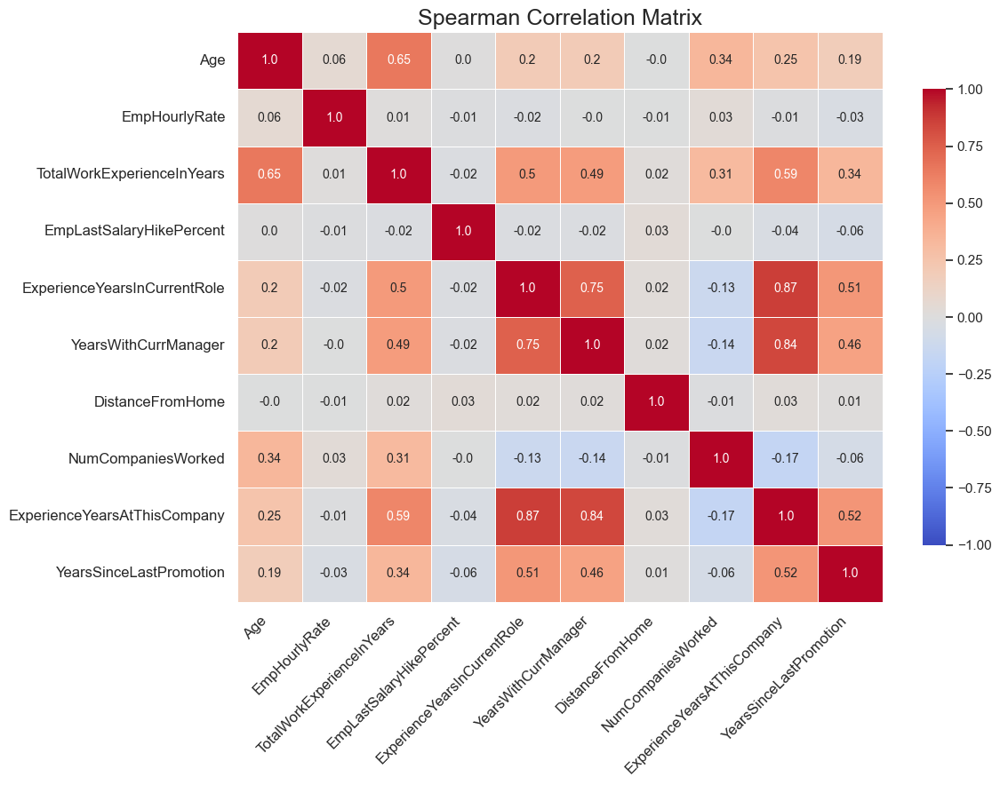

In [47]:
spearman_correlation(
    data,
    data_not_normal_df,
    exclude_target="PerformanceRating",
    multicollinearity_threshold=0.8,
)

Strong positive correlations are seen between ExperienceYearsInCurrentRole and ExperienceYearsAtThisCompany (0.87), and also between YearsWithCurrManager and ExperienceYearsAtThisCompany (0.84), indicating multicollinearity. These variables largely overlap in what they measure—tenure within the company or under one manager—so including all three in a model may cause redundancy. TotalWorkExperienceInYears shows good positive links with both age (0.65) and company experience (0.59), supporting its use as a seniority indicator. Other features like DistanceFromHome and EmpHourlyRate have negligible relationships with the rest. Normality tests confirm none of the numerical variables follow a normal distribution; all have skewness and kurtosis, with YearsSinceLastPromotion being the most skewed and heavy-tailed. These patterns point toward the need for transformation or robust models that can handle non-normal, skewed data.

----

next in data_preprocess, the data will be cleaned, structured, and ready for model training.